# ROI_processing

In [62]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os 
import numpy as np
import pandas as pd
import sys
import seaborn as sns

parent_dir = os.path.abspath(os.path.join(os.getcwd(), '../src/troutpy_reproducibility'))
# Add parent directory to sys.path
sys.path.append(parent_dir)

from batch_running import *

In [63]:

# Define base output directory
base_figures_dir = "/media/sergio/Meninges/troutpy/parameter_tuning/saisnsc/xenium_msbrain_5k/figures"

# Initialize lists to collect data
summary_list = []
xrna_metadata_list = []

# Iterate through each parameter folder
for param_suffix in os.listdir(base_figures_dir):
    folder_path = os.path.join(base_figures_dir, param_suffix)
    folder_path = os.path.join(folder_path, param_suffix)
    summary_path = os.path.join(folder_path, "pipeline_summary.csv")
    xrna_metadata_path = os.path.join(folder_path, "pipeline_xrna_metadata.csv")
    
    if os.path.isfile(summary_path) and os.path.isfile(xrna_metadata_path):
        # Read and annotate summary
        summary_df = pd.read_csv(summary_path)
        summary_df["param_set"] = param_suffix
        summary_list.append(summary_df)
        
        # Read and annotate xrna metadata
        xrna_df = pd.read_csv(xrna_metadata_path)
        proportion=xrna_df[['extracellular_proportion']]
        proportion.columns=[param_suffix]
        xrna_metadata_list.append(proportion)

# Combine all
combined_summary = pd.concat(summary_list, ignore_index=True)
combined_xrna_metadata = pd.concat(xrna_metadata_list,axis=1)


##  Combine xrna proportions across runs

In [16]:
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

# filter xrna metadata
combined_xrna_metadata=combined_xrna_metadata[np.sum(combined_xrna_metadata.isna(),axis=1)==0]
# Compute cosine similarity between parameter sets (columns)
cos_sim_matrix = cosine_similarity(combined_xrna_metadata.T)
# Turn it into a labeled DataFrame
cos_sim_df = pd.DataFrame(cos_sim_matrix,index=combined_xrna_metadata.columns,columns=combined_xrna_metadata.columns)


In [17]:
cos_sim_df.shape

(36, 36)

<Figure size 600x500 with 0 Axes>

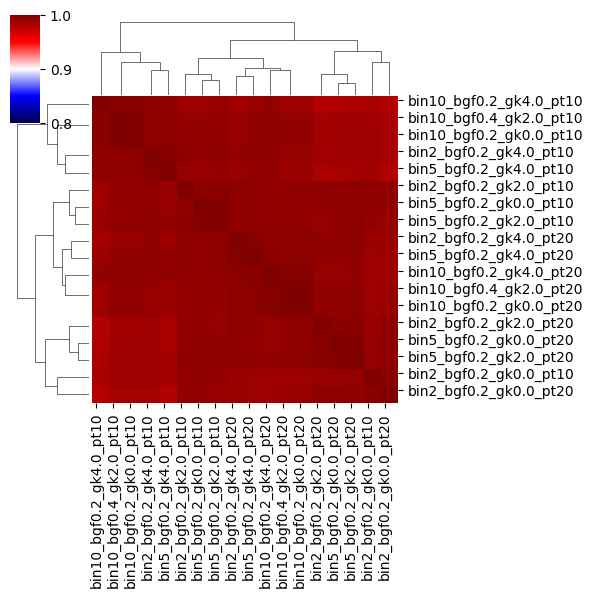

In [18]:
plt.figure(figsize=(6, 5))
sns.clustermap(cos_sim_df,vmin=0.8,vmax=1,cmap='seismic',figsize=(6,6),)

Text(0, 0.5, 'Percentage of extracellular in: bin10_bgf0.2_gk4.0_pt10')

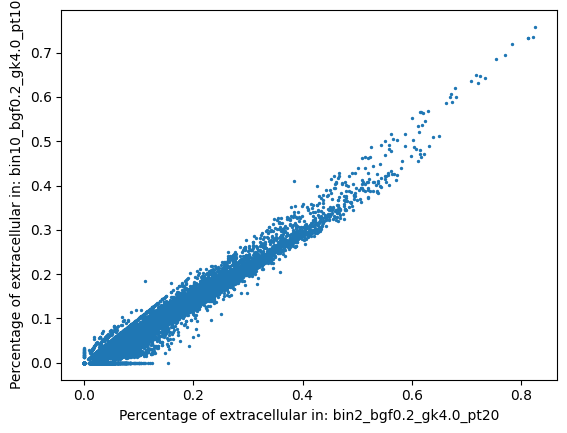

In [42]:
plt.scatter(combined_xrna_metadata.iloc[:,0],combined_xrna_metadata.iloc[:,5],s=2)
plt.xlabel('Percentage of extracellular in: '+combined_xrna_metadata.columns[0])
plt.ylabel('Percentage of extracellular in: '+combined_xrna_metadata.columns[5])

In [21]:
nuclear_housekeeping_genes = [
    "Lmnb1",
    "Ncl",
    "Hnrnpa1",
    "Npm1",
    "Polr2a"
]


combined_xrna_metadata[combined_xrna_metadata.index.isin(nuclear_housekeeping_genes)]

,bin2_bgf0.2_gk4.0_pt20,bin10_bgf0.2_gk0.0_pt10,bin10_bgf0.2_gk0.0_pt20,bin10_bgf0.2_gk2.0_pt10,bin10_bgf0.2_gk2.0_pt20,bin10_bgf0.2_gk4.0_pt10,bin10_bgf0.2_gk4.0_pt20,bin10_bgf0.4_gk0.0_pt10,bin10_bgf0.4_gk0.0_pt20,bin10_bgf0.4_gk2.0_pt10,...,bin5_bgf0.2_gk2.0_pt10,bin5_bgf0.2_gk2.0_pt20,bin5_bgf0.2_gk4.0_pt10,bin5_bgf0.2_gk4.0_pt20,bin5_bgf0.4_gk0.0_pt10,bin5_bgf0.4_gk0.0_pt20,bin5_bgf0.4_gk2.0_pt10,bin5_bgf0.4_gk2.0_pt20,bin5_bgf0.4_gk4.0_pt10,bin5_bgf0.4_gk4.0_pt20


### Plot propotion of exRNA identified

In [26]:
combined_summary=combined_summary.sort_values(by='proportion_of_extracellular')

<Axes: ylabel='param_set'>

<Figure size 500x4000 with 0 Axes>

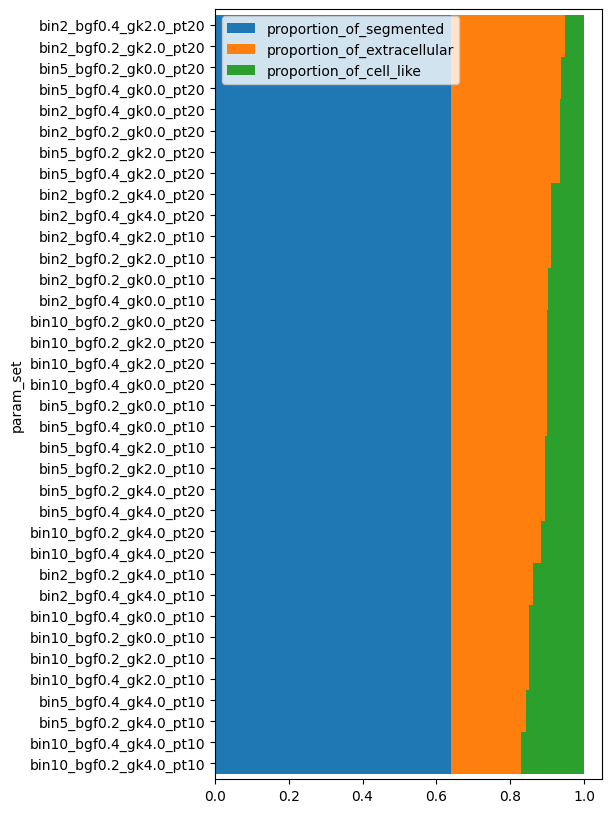

In [34]:
# plot combined summary as bar plot
plt.figure(figsize=(5,40))
combined_summary.plot(kind='barh',stacked=True,width=1,figsize=(5,10))

Text(0, 0.5, 'Assignment')

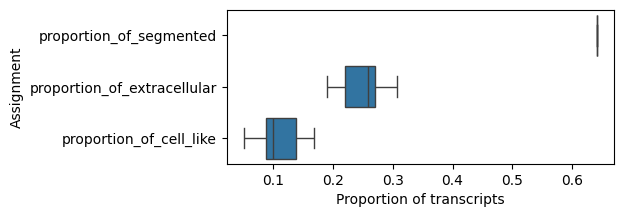

In [56]:
unstacked_combined=combined_summary.unstack().reset_index()
plt.figure(figsize=(5,2))
sns.boxplot(data=unstacked_combined,y='level_0',x=0,color=)
plt.xlabel('Proportion of transcripts')
plt.ylabel('Assignment')

In [ ]:

# Save if needed
combined_summary.to_csv("/media/sergio/Meninges/troutpy/parameter_tuning/combined_summary.csv", index=False)
combined_xrna_metadata.to_csv("/media/sergio/Meninges/troutpy/parameter_tuning/combined_xrna_metadata.csv", index=False)

print("Combined files saved.")


# Permutation test adding

In [64]:
inpath = "/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k"

## defining parameters
binsize=[5,10,2]
background_filter=[0.2,0.4]
gaussian_kernel_key=[0.0,2.0,4.0]
percentile_threshold=[10,20]


In [65]:
param_suffix = f"permutation"
outpath_data = os.path.join("/media/sergio/Meninges/troutpy/parameter_tuning/saisnsc/xenium_msbrain_5k/data", param_suffix)
outpath_figures = os.path.join("/media/sergio/Meninges/troutpy/parameter_tuning/saisnsc/xenium_msbrain_5k/figures", param_suffix)

In [66]:
zarr_path = os.path.join('/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed_with_scores.zarr')
sdata = sd.read_zarr(zarr_path) if hasattr(sd, 'read_zarr') else SpatialData.read(zarr_path)

In [67]:

 # Define output folders
data_output_dir = os.path.join(outpath_data, param_suffix)
figures_output_dir = os.path.join(outpath_figures, param_suffix)
os.makedirs(data_output_dir, exist_ok=True)
os.makedirs(figures_output_dir, exist_ok=True)

# Load data
zarr_path = os.path.join('/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed_with_scores.zarr')

Proportion of cells retained after filtering: 100.00%
Final adata shape: (9185, 4240)


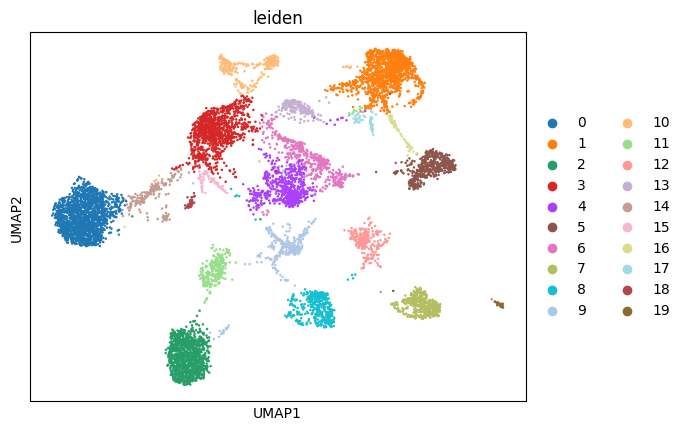

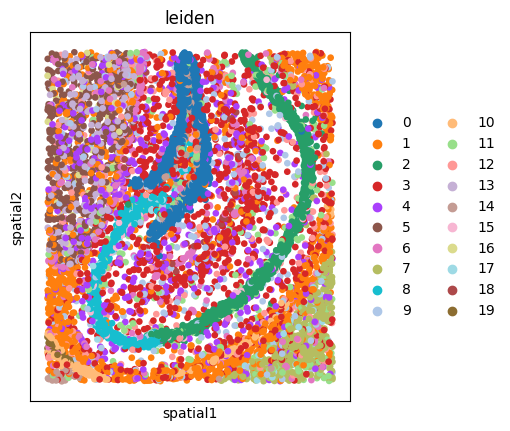

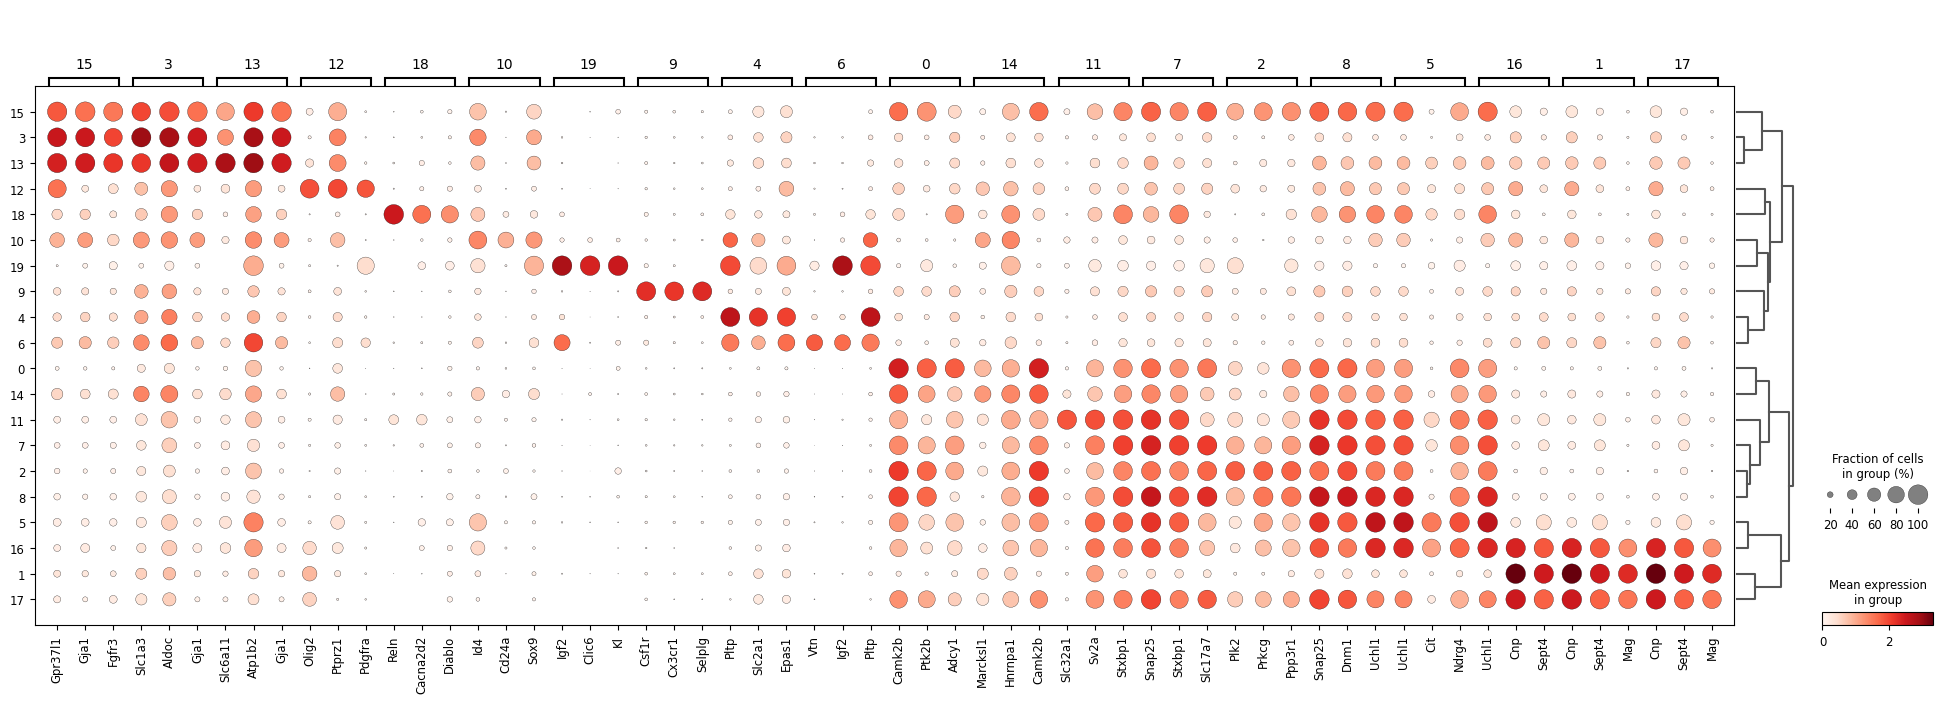

AnnData object with n_obs × n_vars = 9185 × 4240
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'n_genes', 'n_counts', 'leiden', 'cell_type', 'urna_contribution_score', 'normalized_urna_contribution_score', 'urna_source_score'
    var: 'gene_ids', 'feature_types', 'genome', 'gene_id', 'n_cells'
    uns: 'dendrogram_leiden', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'rank_genes_groups', 'spatialdata_attrs', 'umap'
    obsm: 'X_pca', 'X_umap', 'factors_cell_loadings', 'spatial'
    varm: 'PCs'
    layers: 'raw'
    obsp: 'connectivities', 'distances'

In [68]:

meta_path = os.path.join(inpath, 'metadata.csv')
sdata = sd.read_zarr(zarr_path) if hasattr(sd, 'read_zarr') else SpatialData.read(zarr_path)
metadata = pd.read_csv(meta_path)

# 1) Clustering

clustering_pipeline(sdata)

In [69]:
from functools import partial
from multiprocessing import Pool

import numpy as np
import pandas as pd
import polars as pl
import spatialdata
import spatialdata as sd
from sainsc import LazyKDE  # assuming LazyKDE is available
from scipy.sparse import coo_matrix
from sklearn.neighbors import KDTree


def compute_extracellular_counts(data_extracell):  # would be good to change the name of this function
    """
    Compute observed, expected, and fold ratio for extracellular transcript counts.

    Parameters
    ----------
    data_extracell: pandas.DataFrame
        Data with extracellular transcripts.

    Returns
    -------
    pandas.DataFrame
        Dataframe with observed, expected counts, fold ratios, and gene categories.
    """
    extracellular_counts = data_extracell.groupby("feature_name").count()
    extracellular_counts = pd.DataFrame({"observed": extracellular_counts.iloc[:, 0]})
    extracellular_counts["expected"] = int(extracellular_counts["observed"].sum() / extracellular_counts.shape[0])

    # Calculate fold ratios
    extracellular_counts["fold_ratio"] = np.log(extracellular_counts["observed"] / extracellular_counts["expected"])

    # Map gene categories
    gene2cat = dict(zip(data_extracell["feature_name"], data_extracell["codeword_category"], strict=False))
    extracellular_counts["codeword_category"] = extracellular_counts.index.map(gene2cat)

    return extracellular_counts


def define_urna(
    sdata: spatialdata.SpatialData,
    layer: str = "transcripts",
    method: str = "segmentation_free",
    min_prop_of_extracellular: float = 0.8,
    unassigned_tag: str = "UNASSIGNED",
    copy: bool = False,
    percentile_threshold: float = 10,
):
    """
    Identifies unassigned transcripts based on the specified method and updates the spatial data object accordingly.

    Parameters
    ----------
    sdata : spatialdata.SpatialData
        A spatial data object containing transcriptomic information.
    layer : str
        The layer in `sdata.points` containing the transcript data to process.
    method : str
        The method to define extracellular transcripts. Options:
            - 'spots2regions': Uses segmentation-free clustering results.
            - 'sainsc': Uses sainsc-derived signature matching.
            - 'nuclei': Uses overlap with nuclear annotations to classify extracellular transcripts.
            - 'cells': Classifies transcripts not assigned to a cell as extracellular.
    min_prop_of_extracellular : float
        Minimum proportion of transcripts in a cluster required to be extracellular for it to be classified as such
        (used only with the 'spots2regions' method).
    unassigned_tag : str
        Tag indicating transcripts not assigned to any cell.
    copy : bool
        If True, returns a copy of the updated spatial data. If False, updates the `sdata` object in-place.

    Returns
    -------
    Optional: spatialdata.SpatialData
        If `copy` is True, returns a copy of the updated `sdata` object. Otherwise, updates the `sdata` object in-place and returns None.

    Notes
    -----
    - For the 'spots2regions' method, clustering results are used to determine extracellular transcripts.
    - The 'sainsc' method defines extracellular transcripts as those that are not assigned to any cell
      and whose local signature (match_cell_signature) is not False.
    - The 'nuclei' method classifies transcripts outside nuclei as extracellular.
    - The 'cells' method classifies transcripts unassigned to cells as extracellular.
    """
    import pandas as pd  # Ensure pandas is imported, if not already available in sdata environment

    # Compute the data layer from the spatial data object
    data = sdata.points[layer].compute()

    # Method: Segmentation-free clustering (spots2regions)
    if method == "spots2regions":
        data["overlaps_cell"] = (data["cell_id"] != unassigned_tag).astype(int)
        overlapping_cell = pd.crosstab(data["segmentation_free_clusters"], data["overlaps_cell"])
        # Compute proportions and define extracellular clusters
        cluster_totals = overlapping_cell.sum(axis=1)
        cluster_proportions = overlapping_cell.div(cluster_totals, axis=0)
        extracellular_clusters = cluster_proportions[cluster_proportions.loc[:, 0] >= min_prop_of_extracellular].index
        data["extracellular"] = ~data["segmentation_free_clusters"].isin(extracellular_clusters)

    # Method: Using sainsc analysis results
    elif method == "sainsc":
        # Here we define extracellular transcripts as those that:
        # 1. Are not assigned to any cell (cell_id equals unassigned_tag), and
        # 2. Have a match_cell_signature that is not False (i.e. have a cell-like signature locally).
        cosine_sim_threshold = np.nanpercentile(data.loc[data["overlaps_cell"], "cosine_similarity"], percentile_threshold)
        data["match_cell_signature"] = data["cosine_similarity"] > cosine_sim_threshold
        data["extracellular"] = (~data["overlaps_cell"]) & (~data["match_cell_signature"])
        print(f"Cosine similarity threshold for extracellular definition: {cosine_sim_threshold}")
    # Method: Based on nuclei overlap
    elif method == "nuclei":
        data["extracellular"] = data["overlaps_nucleus"] != 1

    # Method: Based on cell assignment
    elif method == "cells":
        data["extracellular"] = data["cell_id"] == unassigned_tag

    # Unsupported method
    else:
        raise ValueError(f"Unknown method: {method}. Supported methods are 'spots2regions', 'sainsc', 'nuclei', and 'cells'.")

    # Update the spatial data object with the new extracellular column
    sdata.points[layer] = sd.models.PointsModel.parse(data)

    return sdata if copy else None


def filter_urna(
    sdata,
    min_counts=None,
    min_extracellular_proportion=None,
    control_probe=None,
    min_logfoldratio_over_noise=1,
    min_morani=None,
    gene_key="feature_name",
    filter_cellular=False,
    copy=False,
    genes_in_segmented=False,
    table_key="table",
):
    """
    Filters xRNA based on specified criteria and updates the sdata object.

    Parameters
    ----------
        sdata: spatialdata.SpatialData
            Spatial data object containing xRNA metadata and transcript information.
        min_counts: int
            Minimum count threshold for xRNA selection.
        min_extracellular_proportion: float
            Minimum extracellular proportion threshold for xRNA selection.
        control_probe: bool
            If False, filters out control probes.
        min_logfoldratio_over_noise: float
            Minimum log fold-change over noise threshold for xRNA selection.
        min_morani: float
            Minimum Moran's I threshold for spatial autocorrelation.
        gene_key: str
            Key for accessing gene names in transcript tables.
        filter_cellular: bool
            If True, also filters the cellular table.
        copy: bool
            If True, returns a filtered copy of sdata; otherwise, modifies in place.
        genes_in_segmented: bool
            Whether to filter genes only present in segmented cells, which should be in sdata[table_key].var.index
        table_key: str
            Name of the table included in sdata, containing an anndata of segmented cells.

    Returns
    -------
        dict-like or None
            Filtered sdata if copy=True, else modifies sdata in place and returns None.
    """
    if copy:
        sdata = sdata.copy()

    # Select genes based on the first provided criterion
    if min_counts is not None:
        selected_genes = sdata["xrna_metadata"].var[sdata["xrna_metadata"].var["count"] > min_counts].index
    if min_extracellular_proportion is not None:
        selected_genes = sdata["xrna_metadata"].var[sdata["xrna_metadata"].var["extracellular_proportion"] > min_extracellular_proportion].index
    elif control_probe is False:
        selected_genes = sdata["xrna_metadata"].var[not sdata["xrna_metadata"].var["control_probe"]].index
    elif min_logfoldratio_over_noise is not None:
        selected_genes = sdata["xrna_metadata"].var[sdata["xrna_metadata"].var["logfoldratio_over_noise"] > min_logfoldratio_over_noise].index
    if min_morani is not None:
        selected_genes = sdata["xrna_metadata"].var[sdata["xrna_metadata"].var["moran_I"] > min_morani].index
    if genes_in_segmented:
        selected_genes = [g for g in sdata["xrna_metadata"].var.index if g in sdata[table_key].var.index]

    # Filter transcripts
    sdata["transcripts"] = sdata["transcripts"][sdata["transcripts"][gene_key].compute().isin(selected_genes)]

    # Filter other related tables safely
    for key in ["segmentation_free_table", "xrna_metadata"]:
        if key in sdata and hasattr(sdata[key], "var"):
            # mask = sdata[key].var.index.isin(selected_genes)
            try:
                sdata[key] = sdata[key][:, sdata[key].var.index.isin(selected_genes)]
            except KeyError:
                pass

    # Filter source_score and target_score by obs
    for key in ["source_score", "target_score"]:
        if key in sdata:
            try:
                sdata[key] = sdata[key][sdata[key].obs[gene_key].isin(selected_genes), :]
            except KeyError:
                pass

    # Filter cellular table if requested
    if filter_cellular and "table" in sdata:
        try:
            sdata["table"] = sdata["table"][:, sdata["table"].var.index.isin(selected_genes)]
        except KeyError:
            pass

    return sdata if copy else None


def process_dataframe(df: pl.DataFrame, binsize: float, n_threads: int = 4):
    """Process a Polars DataFrame by binning spatial coordinates, converting the gene column to categorical, and constructing sparse matrices for each gene."""
    # Compute bin coordinates.
    df = df.with_columns((df["x"] / binsize).floor().alias("bin_x"), (df["y"] / binsize).floor().alias("bin_y"))
    # Shift coordinates so that bins start at zero.
    df = df.with_columns(
        (df["bin_x"] - df["bin_x"].min()).cast(pl.Int32).alias("bin_x"), (df["bin_y"] - df["bin_y"].min()).cast(pl.Int32).alias("bin_y")
    )
    # Ensure count column exists; if not, add one.
    if "count" not in df.columns:
        df = df.with_columns(pl.lit(1, dtype=pl.UInt32).alias("count"))
    else:
        df = df.with_columns(df["count"].cast(pl.UInt32))
    # Make gene column categorical.
    df = df.with_columns(df["gene"].cast(pl.Categorical))

    # Determine grid shape from binned coordinates.
    shape = (df["bin_x"].max() + 1, df["bin_y"].max() + 1)

    # Partition by gene for parallel processing.
    gene_groups = df.partition_by("gene", maintain_order=False)
    process_gene_partial = partial(process_gene, shape=shape)

    with Pool(n_threads) as pool:
        gene_results = pool.map(process_gene_partial, gene_groups)

    results = {}
    for gene, matrix in gene_results:
        results[gene] = matrix

    return results, shape, df


def process_gene(group, shape):
    """Process a group corresponding to one gene to build a sparse matrix."""
    gene_name = group["gene"][0]
    x = group["bin_x"].to_numpy()
    y = group["bin_y"].to_numpy()
    counts = group["count"].to_numpy()
    sparse_matrix = coo_matrix((counts, (x, y)), shape=shape).tocsr()
    return gene_name, sparse_matrix


def segmentation_free_sainsc(
    sdata,
    binsize=3,
    celltype_key="leiden",
    background_filter=0.4,
    gaussian_kernel_key=2.5,
    n_threads=16,
    resolution=1000,
    codeword_category="predesigned_gene",
    return_sainsc=False,
    copy=False,
    # Defaults for missing bin info
    default_cell_type="unknown",
    default_numeric=np.nan,
):
    """
    Process an sdata object by running an integrated sainsc analysis pipeline with configurable parameters.

    Steps:
      1. Extract and filter transcript data.
      2. Compute cell type signatures.
      3. For KDE/cell type assignment, use only transcripts with overlapping genes.
      4. Bin all transcripts.
      5. Merge the bin-level metadata (computed from successful bins) back to the full transcript set.
      6. For transcripts that do NOT obtain metadata via the merge, assign them the data
         from their spatially closest neighbor (based on "x", "y").
    """
    # --- 1. Prepare Transcript Data ---
    transcripts_all = sdata.points["transcripts"][["gene", "x", "y", "transcript_id"]].compute().reset_index(drop=True)
    # transcripts_all = transcripts_all[transcripts_all["codeword_category"] == codeword_category]
    transcripts_all = transcripts_all[transcripts_all["gene"].astype(str) != "nan"]

    # Create a full DataFrame for binning (all transcripts are retained)
    transcripts_full = pl.from_pandas(transcripts_all[["gene", "x", "y"]].copy(), schema_overrides={"gene": pl.Categorical})

    # --- 2. Retrieve Cell Expression Data & Compute Signatures ---
    adata = sdata["table"]
    expr = adata.to_df()
    expr["cell type"] = adata.obs[celltype_key]
    signatures = expr.groupby("cell type").mean().transpose()

    # --- 3. Determine Overlapping Genes for Analysis ---
    common_genes = set(transcripts_all["gene"].unique()).intersection(set(signatures.index))
    transcripts_analysis = transcripts_full.filter(pl.col("gene").is_in(list(common_genes)))

    # Filter the signature matrix to match KDE
    signatures = signatures.loc[signatures.index.isin(common_genes), :]
    #
    # --- 4. Create Brain Object Using LazyKDE (Analysis on overlapping genes) ---
    brain = LazyKDE.from_dataframe(transcripts_analysis, resolution=resolution, binsize=binsize, n_threads=n_threads)

    # --- 5. Process All Transcripts into Binned Data ---
    _, shape, transcript2bin_info = process_dataframe(transcripts_full, binsize=binsize, n_threads=n_threads)
    transcript2bin_info = transcript2bin_info.to_pandas()
    transcript2bin_info["bin_x_y_id"] = transcript2bin_info["bin_x"].astype(str) + "_" + transcript2bin_info["bin_y"].astype(str)

    # --- 6. Prepare Unique Identifiers for Merging ---
    # Round coordinates to create matching keys.
    transcripts_all["x"] = transcripts_all["x"].round(4)
    transcripts_all["y"] = transcripts_all["y"].round(4)
    transcript2bin_info["x"] = transcript2bin_info["x"].round(4)
    transcript2bin_info["y"] = transcript2bin_info["y"].round(4)
    transcripts_all["xy"] = transcripts_all["x"].astype(str) + "_" + transcripts_all["y"].astype(str)
    transcript2bin_info["xy"] = transcript2bin_info["x"].astype(str) + "_" + transcript2bin_info["y"].astype(str)

    # --- 7. Run KDE, Background Filtering and Cell Type Assignment ---
    brain.calculate_total_mRNA()
    brain.gaussian_kernel(gaussian_kernel_key, unit="um")
    brain.calculate_total_mRNA_KDE()
    brain.filter_background(background_filter)
    brain.assign_celltype(signatures, log=True)

    # --- 8. Compute Bin-level Features from Brain ---
    celltype_flat = brain.celltype_map.flatten()
    assignment_score_flat = brain.assignment_score.flatten()
    cosine_similarity_flat = brain.cosine_similarity.flatten()

    n_rows, n_cols = brain.celltype_map.shape
    x_coords, y_coords = np.meshgrid(np.arange(n_cols), np.arange(n_rows))
    x_coords = x_coords.flatten()
    y_coords = y_coords.flatten()

    output_df = pd.DataFrame(
        {
            "bin_x": x_coords,
            "bin_y": y_coords,
            "cell type": celltype_flat,
            "assignment_score": assignment_score_flat,
            "cosine_similarity": cosine_similarity_flat,
        }
    )
    num2ct = dict(zip(range(len(brain.celltypes)), brain.celltypes, strict=False))
    output_df["cell type"] = output_df["cell type"].map(num2ct)
    output_df["bin_x_y_id"] = output_df["bin_y"].astype(str) + "_" + output_df["bin_x"].astype(str)

    # Build mapping dictionaries.
    bin2celltype = dict(zip(output_df["bin_x_y_id"], output_df["cell type"], strict=False))
    bin2cosine = dict(zip(output_df["bin_x_y_id"], list(output_df["cosine_similarity"]), strict=False))
    bin2assign = dict(zip(output_df["bin_x_y_id"], list(output_df["assignment_score"]), strict=False))

    # --- 9. Merge Bin-level Features for Transcripts That Were Successfully Binned ---
    # Merge on the unique "xy" identifier.
    bin_features = transcript2bin_info[["xy", "bin_x_y_id"]].drop_duplicates()
    bin_features["closest_cell_type"] = bin_features["bin_x_y_id"].map(bin2celltype)
    bin_features["cosine_similarity"] = bin_features["bin_x_y_id"].map(bin2cosine)
    bin_features["assignment_score"] = bin_features["bin_x_y_id"].map(bin2assign)

    # Perform a left merge so all transcripts are retained.
    merged = pd.merge(transcripts_all, bin_features, on="xy", how="left")

    # --- 10. Apply Nearest-Neighbor Assignment Only When Merge Failed ---
    missing_mask = merged["closest_cell_type"].isna()
    if missing_mask.sum() > 0:
        # Use only transcripts that have valid bin metadata.
        valid = merged[~missing_mask]
        missing = merged[missing_mask]
        if not valid.empty:
            # Build KDTree using the positions (x,y) of valid transcripts.
            tree = KDTree(valid[["x", "y"]].values)
            distances, indices = tree.query(missing[["x", "y"]].values, k=1)
            nn_metadata = valid.iloc[indices.flatten()].reset_index(drop=True)
            for col in ["closest_cell_type", "cosine_similarity", "assignment_score"]:
                missing[col] = nn_metadata[col].values
            merged.loc[missing_mask, ["closest_cell_type", "cosine_similarity", "assignment_score", "match_cell_signature"]] = missing[
                ["closest_cell_type", "cosine_similarity", "assignment_score"]
            ]

    # --- 11. Fill Any Remaining Missing Values with Defaults ---
    merged["closest_cell_type"] = merged["closest_cell_type"].fillna(default_cell_type)
    merged["cosine_similarity"] = merged["cosine_similarity"].fillna(default_numeric)
    merged["assignment_score"] = merged["assignment_score"].fillna(default_numeric)

    # Optionlly, force the correct data types
    merged["closest_cell_type"] = merged["closest_cell_type"].astype(str)
    merged["cosine_similarity"] = merged["cosine_similarity"].astype(float)
    merged["assignment_score"] = merged["assignment_score"].astype(float)

    # --- 12. Update the sdata Object ---
    transi = sdata.points["transcripts"].compute().copy()
    transi["xy"] = transi["x"].round(4).astype(str) + "_" + transi["y"].round(4).astype(str)
    # Drop duplicated columns if needed
    columns_to_remove = ["closest_cell_type", "cosine_similarity", "assignment_score"]
    cols_to_drop = [col for col in columns_to_remove if col in transi.columns]
    transi = transi.drop(columns=cols_to_drop)

    # Then merge safely
    transi = pd.merge(
        transi,
        merged[["xy", "closest_cell_type", "cosine_similarity", "assignment_score"]],
        on="xy",
        how="left",
    )
    # Fill any remaining missing entries as a safeguard (should be none now)
    transi["closest_cell_type"] = transi["closest_cell_type"].fillna(default_cell_type).astype(str)
    transi["cosine_similarity"] = transi["cosine_similarity"].fillna(default_numeric).astype(float)
    transi["assignment_score"] = transi["assignment_score"].fillna(default_numeric).astype(float)
    # Update the transcripts layer
    sdata.points["transcripts"] = sd.models.PointsModel.parse(transi)

    # --- 13. Return Results ---
    sainsc_output = {"brain": brain, "transcript2bin_info": transcript2bin_info, "output_df": output_df}
    if return_sainsc:
        return sdata, sainsc_output
    else:
        return sdata if copy else None


In [54]:
sdata['table'].obs['leiden']=sdata['table'].obs['cell_type']

In [36]:
    # 2) Segmentation-free SAiNSC
sdata,sainsc_output=segmentation_free_sainsc(
sdata,
        binsize=10,
        celltype_key='leiden',
        background_filter=0.4,
        gaussian_kernel_key=2.0,
        n_threads=1,return_sainsc=True)

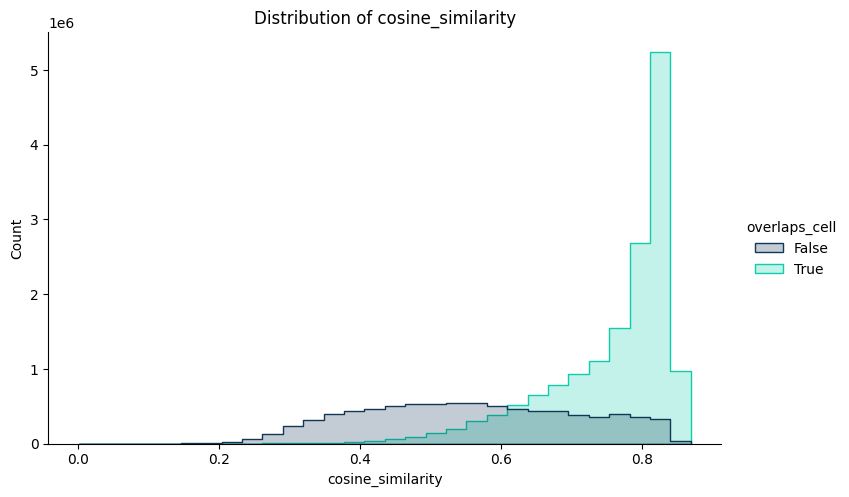

In [37]:
# 3) Histogram of scores
troutpy.pl.histogram(sdata,x='cosine_similarity',
        hue='overlaps_cell',palette='troutpy',save=False)

# Testing real vs shuffled

In [70]:
import numpy as np
import pandas as pd
import polars as pl
from sklearn.neighbors import KDTree
from sainsc import LazyKDE

def segmentation_free_sainsc_shuff(
    sdata,
    binsize=3,
    celltype_key="leiden",
    background_filter=0.4,
    gaussian_kernel_key=2.5,
    n_threads=16,
    resolution=1000,
    codeword_category="predesigned_gene",
    return_sainsc=False,
    copy=False,
    default_cell_type="unknown",
    default_numeric=np.nan,
    shuffle_genes=False,          # <--- NEW PARAMETER
    random_seed=None              # <--- OPTIONAL FOR REPRODUCIBILITY
):
    """
    Processes sdata and optionally shuffles gene names in transcript data only.

    Parameters
    ----------
    shuffle_genes : bool
        If True, shuffles gene names in the transcripts table.
    random_seed : int, optional
        Seed for reproducible shuffling.
    """
    # --- 1. Prepare Transcript Data ---
    transcripts_all = sdata.points["transcripts"][["gene", "x", "y", "transcript_id"]].compute().reset_index(drop=True)
    transcripts_all = transcripts_all[transcripts_all["gene"].astype(str) != "nan"]

    # --- 1A. Shuffle Gene Names (only transcript data) ---
    if shuffle_genes:
        if random_seed is not None:
            np.random.seed(random_seed)
        unique_genes = transcripts_all["gene"].unique()
        shuffled_genes = np.random.permutation(unique_genes)
        gene_map = dict(zip(unique_genes, shuffled_genes))
        transcripts_all["gene"] = transcripts_all["gene"].map(gene_map)

    # --- 2. Convert to Polars for binning ---
    transcripts_full = pl.from_pandas(transcripts_all[["gene", "x", "y"]].copy(), schema_overrides={"gene": pl.Categorical})

    # --- 3. Retrieve Cell Expression Data & Compute Signatures ---
    adata = sdata["table"]
    expr = adata.to_df()
    expr["cell type"] = adata.obs[celltype_key]
    signatures = expr.groupby("cell type").mean().transpose()

    # --- 4. Determine Overlapping Genes ---
    common_genes = set(transcripts_all["gene"].unique()).intersection(set(signatures.index))
    transcripts_analysis = transcripts_full.filter(pl.col("gene").is_in(list(common_genes)))
    signatures = signatures.loc[signatures.index.isin(common_genes), :]

    # --- 5. Create KDE Brain ---
    brain = LazyKDE.from_dataframe(transcripts_analysis, resolution=resolution, binsize=binsize, n_threads=n_threads)

    # --- 6. Process All Transcripts into Binned Data ---
    _, shape, transcript2bin_info = process_dataframe(transcripts_full, binsize=binsize, n_threads=n_threads)
    transcript2bin_info = transcript2bin_info.to_pandas()
    transcript2bin_info["bin_x_y_id"] = transcript2bin_info["bin_x"].astype(str) + "_" + transcript2bin_info["bin_y"].astype(str)

    # --- 7. Prepare Unique Identifiers ---
    transcripts_all["x"] = transcripts_all["x"].round(4)
    transcripts_all["y"] = transcripts_all["y"].round(4)
    transcript2bin_info["x"] = transcript2bin_info["x"].round(4)
    transcript2bin_info["y"] = transcript2bin_info["y"].round(4)
    transcripts_all["xy"] = transcripts_all["x"].astype(str) + "_" + transcripts_all["y"].astype(str)
    transcript2bin_info["xy"] = transcript2bin_info["x"].astype(str) + "_" + transcript2bin_info["y"].astype(str)

    # --- 8. Run KDE, Filter, Assign Cell Types ---
    brain.calculate_total_mRNA()
    brain.gaussian_kernel(gaussian_kernel_key, unit="um")
    brain.calculate_total_mRNA_KDE()
    brain.filter_background(background_filter)
    brain.assign_celltype(signatures, log=True)

    # --- 9. Compute Bin-level Features ---
    celltype_flat = brain.celltype_map.flatten()
    assignment_score_flat = brain.assignment_score.flatten()
    cosine_similarity_flat = brain.cosine_similarity.flatten()
    n_rows, n_cols = brain.celltype_map.shape
    x_coords, y_coords = np.meshgrid(np.arange(n_cols), np.arange(n_rows))
    x_coords = x_coords.flatten()
    y_coords = y_coords.flatten()

    output_df = pd.DataFrame({
        "bin_x": x_coords,
        "bin_y": y_coords,
        "cell type": celltype_flat,
        "assignment_score": assignment_score_flat,
        "cosine_similarity": cosine_similarity_flat,
    })
    num2ct = dict(zip(range(len(brain.celltypes)), brain.celltypes))
    output_df["cell type"] = output_df["cell type"].map(num2ct)
    output_df["bin_x_y_id"] = output_df["bin_y"].astype(str) + "_" + output_df["bin_x"].astype(str)

    # --- 10. Merge Bin Features ---
    bin_features = transcript2bin_info[["xy", "bin_x_y_id"]].drop_duplicates()
    bin_features["closest_cell_type"] = bin_features["bin_x_y_id"].map(dict(zip(output_df["bin_x_y_id"], output_df["cell type"])))
    bin_features["cosine_similarity"] = bin_features["bin_x_y_id"].map(dict(zip(output_df["bin_x_y_id"], output_df["cosine_similarity"])))
    bin_features["assignment_score"] = bin_features["bin_x_y_id"].map(dict(zip(output_df["bin_x_y_id"], output_df["assignment_score"])))

    merged = pd.merge(transcripts_all, bin_features, on="xy", how="left")

    # --- 11. Nearest Neighbor Fill ---
    missing_mask = merged["closest_cell_type"].isna()
    if missing_mask.sum() > 0:
        valid = merged[~missing_mask]
        missing = merged[missing_mask]
        if not valid.empty:
            tree = KDTree(valid[["x", "y"]].values)
            distances, indices = tree.query(missing[["x", "y"]].values, k=1)
            nn_metadata = valid.iloc[indices.flatten()].reset_index(drop=True)
            for col in ["closest_cell_type", "cosine_similarity", "assignment_score"]:
                missing[col] = nn_metadata[col].values
            merged.loc[missing_mask, ["closest_cell_type", "cosine_similarity", "assignment_score"]] = missing[
                ["closest_cell_type", "cosine_similarity", "assignment_score"]
            ]

    # --- 12. Fill Remaining ---
    merged["closest_cell_type"] = merged["closest_cell_type"].fillna(default_cell_type)
    merged["cosine_similarity"] = merged["cosine_similarity"].fillna(default_numeric)
    merged["assignment_score"] = merged["assignment_score"].fillna(default_numeric)

    # --- 13. Store Back ---
    sdata.points["transcripts"] = sd.models.PointsModel.parse(merged)

    if return_sainsc:
        return sdata, brain
    return sdata if copy else None


def segmentation_free_sainsc_permutation_test(
    sdata,
    n_iterations=100,
    random_seed=None,
    **kwargs
):
    """
    Run permutation test with real vs shuffled gene assignments.

    Stores only summary stats instead of full transcript tables.
    """
    def extract_summary(df):
        return df.groupby("closest_cell_type")["cosine_similarity"].mean()

    # --- Real run ---
    real_out, _ = segmentation_free_sainsc_shuff(
        sdata,
        shuffle_genes=False,
        copy=True,
        return_sainsc=True,
        random_seed=random_seed,
        **kwargs
    )
    real_df = real_out.points["transcripts"].compute()
    real_summary = extract_summary(real_df)

    # --- Shuffled runs ---
    shuffled_summaries = []
    print('Starting shuffling')
    for i in range(n_iterations):
        print(i)
        shuffle_seed = None if random_seed is None else random_seed + i
        shuffled_out, _ = segmentation_free_sainsc_shuff(
            sdata,
            shuffle_genes=True,
            copy=True,
            return_sainsc=True,
            random_seed=shuffle_seed,
            **kwargs
        )
        shuffled_df = shuffled_out.points["transcripts"].compute()
        #shuffled_summary = extract_summary(shuffled_df)
        shuffled_summaries.append(shuffled_df)

    return {"real":  real_df, "shuffled": shuffled_summaries}


In [71]:
results = segmentation_free_sainsc_permutation_test(
    sdata,
    n_iterations=2,
    random_seed=42
)

real = results["real"]
shuffled = results["shuffled"]  # list of DataFrames, one per shuffle


Starting shuffling
0
1


In [85]:
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp

def compare_real_vs_shuffled(results, score_col="cosine_similarity", id_col="transcript_id", two_sided=True):
    """
    Compare real vs shuffled scores globally and per observation.
    Each real score is tested against the pooled shuffled distribution.

    Parameters
    ----------
    results : dict
        {"real": DataFrame, "shuffled": [DataFrame, ...]}
        All dataframes must contain `id_col` and `score_col`.
    score_col : str
        Which score to test ("cosine_similarity" or "assignment_score").
    id_col : str
        Unique identifier ("transcript_id" or "bin_x_y_id").
    two_sided : bool
        If True, compute two-sided empirical p-values per observation.

    Returns
    -------
    dict with:
        - global_test: KS test statistic + p-value
        - global_mean_test: mean-based empirical p-value
        - per_observation: DataFrame with id, real_score, p-value(s)
    """
    real_df = results["real"].set_index(id_col)
    shuffled_dfs = [df.set_index(id_col) for df in results["shuffled"]]

    # --- 1. Global comparison ---
    real_scores = real_df[score_col].values
    shuffled_scores = np.concatenate([df[score_col].values for df in shuffled_dfs])

    ks_stat, ks_p = ks_2samp(real_scores, shuffled_scores)

    T_real = np.mean(real_scores)
    T_shuf = [df[score_col].mean() for df in shuffled_dfs]
    N = len(T_shuf)
    mean_p = (1 + np.sum(np.array(T_shuf) >= T_real)) / (N + 1)

    # --- 2. Per-observation comparison (vs pooled shuffled distribution) ---
    per_obs = real_df[[score_col]].copy()
    per_obs.rename(columns={score_col: "real_score"}, inplace=True)

    if two_sided:
        shuf_mean = np.mean(shuffled_scores)
        abs_dev_real = np.abs(per_obs["real_score"].values - shuf_mean)
        abs_dev_shuf = np.abs(shuffled_scores - shuf_mean)
        pvals = [(1 + np.sum(abs_dev_shuf >= dev)) / (len(shuffled_scores) + 1)
                 for dev in abs_dev_real]
    else:
        # one-sided: how often shuffled >= real
        pvals = [(1 + np.sum(shuffled_scores >= val)) / (len(shuffled_scores) + 1)
                 for val in per_obs["real_score"].values]

    per_obs["empirical_pval"] = pvals
    per_obs.reset_index(inplace=True)

    return {
        "global_test": {"KS_stat": ks_stat, "KS_p": ks_p},
        "global_mean_test": {"T_real": T_real, "T_shuf": T_shuf, "p_value": mean_p},
        "per_observation": per_obs,
    }


In [ ]:
# Compare cosine similarity distributions
comp = compare_real_vs_shuffled(results, score_col="cosine_similarity", id_col="transcript_id")

print("Global KS test:", comp["global_test"])
print("Global mean test:", comp["global_mean_test"])

per_obs = comp["per_observation"]
print(per_obs.head())


In [ ]:
comp['per_observation']

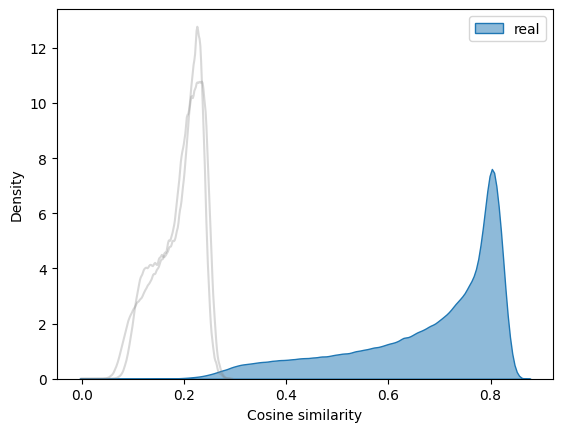

In [74]:
import seaborn as sns

sns.kdeplot(results['real']['cosine_similarity'], label="real", fill=True, alpha=0.5)
for e in results['shuffled']:
    sns.kdeplot(e['cosine_similarity'], color="gray", alpha=0.3)

plt.xlabel("Cosine similarity")
plt.ylabel("Density")
plt.legend()
plt.show()


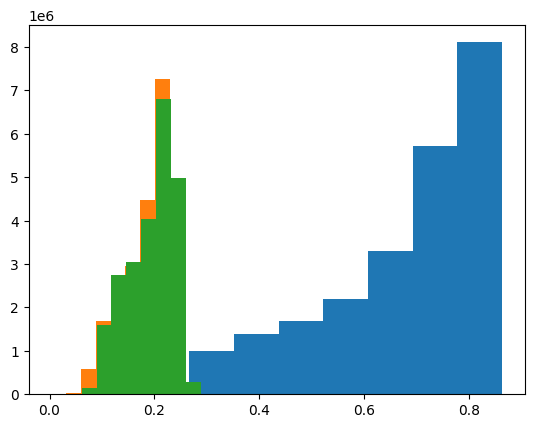

In [61]:
plt.hist(results['real']['cosine_similarity'])
for e in results['shuffled']:
    plt.hist(e['cosine_similarity'])


# Exploring how to shuffle labels in the sainsc_output

In [19]:
genes_shuffled

['Plk4',
 'Ufl1',
 'Krit1',
 'Sntb1',
 'Etv1',
 'Polg',
 'Tyro3',
 'Trpc6',
 'Ddc',
 'Il11ra1',
 'Cops8',
 'C1ql1',
 'Chuk',
 'Acvr1',
 'Il34',
 'Irak2',
 'Rarg',
 'Nfe2l2',
 'Setx',
 'Mbl1',
 'Hck',
 'Tecpr2',
 'C5ar1',
 'Zfp219',
 'Amigo3',
 'Pkd2',
 'Rab4b',
 'Sept7',
 'Zfpl1',
 'Smc5',
 'Ing3',
 'Cic',
 'Ptp4a1',
 'Zc3h12a',
 'Fam49b',
 'Cygb',
 'Ikzf2',
 'Dst',
 'Phf10',
 'Cdk5rap2',
 'Wwox',
 'Sh3bp2',
 'Cntnap1',
 'Fstl1',
 'Sh3bp5',
 'Tmem98',
 'Snapin',
 'Sorcs3',
 'Cdkn1a',
 'Pcna',
 'Egr4',
 'Dvl1',
 'Snx27',
 'Timp4',
 'Gsdme',
 'Borcs8',
 'Crym',
 'E2f1',
 'Atn1',
 'Ptger2',
 'Cd33',
 'Ptpru',
 'Vamp3',
 'Mrnip',
 'Prkcg',
 'Cfap61',
 'Coro6',
 'Erbb3',
 'Pcmtd2',
 'Arf6',
 'Tgm2',
 'Cisd2',
 'Abcc9',
 'Gfra1',
 'Lepr',
 'Gjb1',
 'Nkx6-2',
 'Myo9a',
 'Map7',
 'Slc47a1',
 'Myrf',
 'Hmga1b',
 'Trim17',
 'Glra2',
 'Htr2c',
 'Hps4',
 'Hcrtr2',
 'Itch',
 'Rai14',
 'Psmd11',
 'Pld5',
 'Inpp4b',
 'Ublcp1',
 'Il17rb',
 'Mecom',
 'Mturn',
 'Pgam5',
 'En1',
 'Ptgs2',
 'F2rl3',
 'Cr2

In [21]:
import random
genes_shuffled = sainsc_output['brain'].genes.copy()
random.shuffle(genes_shuffled)

sainsc_output['brain'].genes=genes_shuffled

AttributeError: can't set attribute 'genes'

In [42]:
sainsc_output['brain'].genes[:5]

['Exosc9', 'Actl6a', 'Srp72', 'Grp', 'Gria4']

In [43]:
type(sainsc_output['brain'])


sainsc.lazykde._LazyKDE.LazyKDE

In [22]:
import numpy as np
import pandas as pd
import polars as pl
from sklearn.neighbors import KDTree
from sainsc import LazyKDE

def segmentation_free_sainsc_shuff(
    sdata,
    binsize=3,
    celltype_key="leiden",
    background_filter=0.4,
    gaussian_kernel_key=2.5,
    n_threads=16,
    resolution=1000,
    codeword_category="predesigned_gene",
    return_sainsc=False,
    copy=False,
    default_cell_type="unknown",
    default_numeric=np.nan,
    shuffle_genes=False,          # <--- NEW PARAMETER
    random_seed=None              # <--- OPTIONAL FOR REPRODUCIBILITY
):
    """
    Processes sdata and optionally shuffles gene names in transcript data only.

    Parameters
    ----------
    shuffle_genes : bool
        If True, shuffles gene names in the transcripts table.
    random_seed : int, optional
        Seed for reproducible shuffling.
    """
    # --- 1. Prepare Transcript Data ---
    transcripts_all = sdata.points["transcripts"][["gene", "x", "y", "transcript_id"]].compute().reset_index(drop=True)
    transcripts_all = transcripts_all[transcripts_all["gene"].astype(str) != "nan"]

    # --- 1A. Shuffle Gene Names (only transcript data) ---
    if shuffle_genes:
        if random_seed is not None:
            np.random.seed(random_seed)
        unique_genes = transcripts_all["gene"].unique()
        shuffled_genes = np.random.permutation(unique_genes)
        gene_map = dict(zip(unique_genes, shuffled_genes))
        transcripts_all["gene"] = transcripts_all["gene"].map(gene_map)

    # --- 2. Convert to Polars for binning ---
    transcripts_full = pl.from_pandas(transcripts_all[["gene", "x", "y"]].copy(), schema_overrides={"gene": pl.Categorical})

    # --- 3. Retrieve Cell Expression Data & Compute Signatures ---
    adata = sdata["table"]
    expr = adata.to_df()
    expr["cell type"] = adata.obs[celltype_key]
    signatures = expr.groupby("cell type").mean().transpose()

    # --- 4. Determine Overlapping Genes ---
    common_genes = set(transcripts_all["gene"].unique()).intersection(set(signatures.index))
    transcripts_analysis = transcripts_full.filter(pl.col("gene").is_in(list(common_genes)))
    signatures = signatures.loc[signatures.index.isin(common_genes), :]

    # --- 5. Create KDE Brain ---
    brain = LazyKDE.from_dataframe(transcripts_analysis, resolution=resolution, binsize=binsize, n_threads=n_threads)

    # --- 6. Process All Transcripts into Binned Data ---
    _, shape, transcript2bin_info = process_dataframe(transcripts_full, binsize=binsize, n_threads=n_threads)
    transcript2bin_info = transcript2bin_info.to_pandas()
    transcript2bin_info["bin_x_y_id"] = transcript2bin_info["bin_x"].astype(str) + "_" + transcript2bin_info["bin_y"].astype(str)

    # --- 7. Prepare Unique Identifiers ---
    transcripts_all["x"] = transcripts_all["x"].round(4)
    transcripts_all["y"] = transcripts_all["y"].round(4)
    transcript2bin_info["x"] = transcript2bin_info["x"].round(4)
    transcript2bin_info["y"] = transcript2bin_info["y"].round(4)
    transcripts_all["xy"] = transcripts_all["x"].astype(str) + "_" + transcripts_all["y"].astype(str)
    transcript2bin_info["xy"] = transcript2bin_info["x"].astype(str) + "_" + transcript2bin_info["y"].astype(str)

    # --- 8. Run KDE, Filter, Assign Cell Types ---
    brain.calculate_total_mRNA()
    brain.gaussian_kernel(gaussian_kernel_key, unit="um")
    brain.calculate_total_mRNA_KDE()
    brain.filter_background(background_filter)
    brain.assign_celltype(signatures, log=True)

    # --- 9. Compute Bin-level Features ---
    celltype_flat = brain.celltype_map.flatten()
    assignment_score_flat = brain.assignment_score.flatten()
    cosine_similarity_flat = brain.cosine_similarity.flatten()
    n_rows, n_cols = brain.celltype_map.shape
    x_coords, y_coords = np.meshgrid(np.arange(n_cols), np.arange(n_rows))
    x_coords = x_coords.flatten()
    y_coords = y_coords.flatten()

    output_df = pd.DataFrame({
        "bin_x": x_coords,
        "bin_y": y_coords,
        "cell type": celltype_flat,
        "assignment_score": assignment_score_flat,
        "cosine_similarity": cosine_similarity_flat,
    })
    num2ct = dict(zip(range(len(brain.celltypes)), brain.celltypes))
    output_df["cell type"] = output_df["cell type"].map(num2ct)
    output_df["bin_x_y_id"] = output_df["bin_y"].astype(str) + "_" + output_df["bin_x"].astype(str)

    # --- 10. Merge Bin Features ---
    bin_features = transcript2bin_info[["xy", "bin_x_y_id"]].drop_duplicates()
    bin_features["closest_cell_type"] = bin_features["bin_x_y_id"].map(dict(zip(output_df["bin_x_y_id"], output_df["cell type"])))
    bin_features["cosine_similarity"] = bin_features["bin_x_y_id"].map(dict(zip(output_df["bin_x_y_id"], output_df["cosine_similarity"])))
    bin_features["assignment_score"] = bin_features["bin_x_y_id"].map(dict(zip(output_df["bin_x_y_id"], output_df["assignment_score"])))

    merged = pd.merge(transcripts_all, bin_features, on="xy", how="left")

    # --- 11. Nearest Neighbor Fill ---
    missing_mask = merged["closest_cell_type"].isna()
    if missing_mask.sum() > 0:
        valid = merged[~missing_mask]
        missing = merged[missing_mask]
        if not valid.empty:
            tree = KDTree(valid[["x", "y"]].values)
            distances, indices = tree.query(missing[["x", "y"]].values, k=1)
            nn_metadata = valid.iloc[indices.flatten()].reset_index(drop=True)
            for col in ["closest_cell_type", "cosine_similarity", "assignment_score"]:
                missing[col] = nn_metadata[col].values
            merged.loc[missing_mask, ["closest_cell_type", "cosine_similarity", "assignment_score"]] = missing[
                ["closest_cell_type", "cosine_similarity", "assignment_score"]
            ]

    # --- 12. Fill Remaining ---
    merged["closest_cell_type"] = merged["closest_cell_type"].fillna(default_cell_type)
    merged["cosine_similarity"] = merged["cosine_similarity"].fillna(default_numeric)
    merged["assignment_score"] = merged["assignment_score"].fillna(default_numeric)

    # --- 13. Store Back ---
    sdata.points["transcripts"] = sd.models.PointsModel.parse(merged)

    if return_sainsc:
        return sdata, brain
    return sdata if copy else None


In [23]:
    # 2) Segmentation-free SAiNSC
sdata_shuff,sainsc_output_shuff=segmentation_free_sainsc_shuff(
sdata,binsize=10,celltype_key='leiden',
background_filter=0.4,gaussian_kernel_key=2.0,
n_threads=1,return_sainsc=True,shuffle_genes=True)

In [24]:
sdata

SpatialData object, with associated Zarr store: /media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed_with_scores.zarr
├── Images
│     └── 'morphology_focus': DataTree[cyx] (5, 9300, 8049), (5, 4650, 4025), (5, 2325, 2012), (5, 1162, 1006), (5, 581, 502)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (9300, 8049), (4650, 4025), (2325, 2012), (1162, 1006), (581, 502)
│     └── 'nucleus_labels': DataTree[yx] (9300, 8049), (4650, 4025), (2325, 2012), (1162, 1006), (581, 502)
├── Points
│     ├── 'extracellular_transcripts': DataFrame with shape: (<Delayed>, 21) (3D points)
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 9) (2D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (9289, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (9191, 2) (2D shapes)
│     ├── 'grid_squares': GeoDataFrame shape: (34056, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (9249, 1) (2D shapes)
└── Tables
      ├── 'segmentation_fre

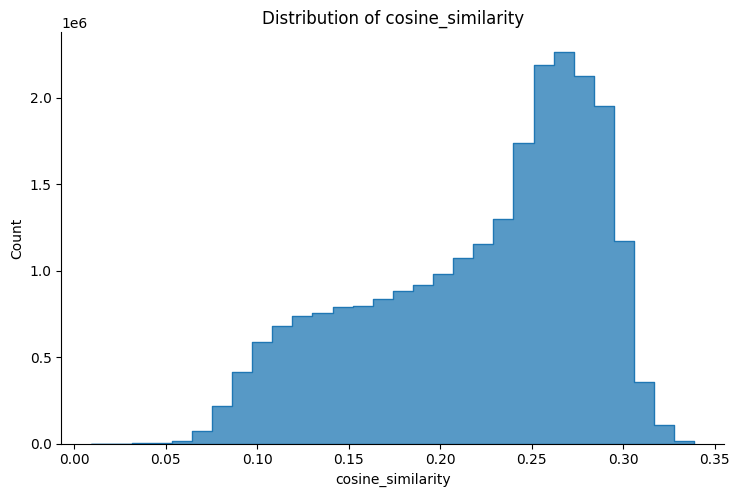

In [25]:
# 3) Histogram of scores
troutpy.pl.histogram(sdata_shuff,x='cosine_similarity',palette='troutpy',save=False)

In [14]:
sdata

SpatialData object, with associated Zarr store: /media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed_with_scores.zarr
├── Images
│     └── 'morphology_focus': DataTree[cyx] (5, 9300, 8049), (5, 4650, 4025), (5, 2325, 2012), (5, 1162, 1006), (5, 581, 502)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (9300, 8049), (4650, 4025), (2325, 2012), (1162, 1006), (581, 502)
│     └── 'nucleus_labels': DataTree[yx] (9300, 8049), (4650, 4025), (2325, 2012), (1162, 1006), (581, 502)
├── Points
│     ├── 'extracellular_transcripts': DataFrame with shape: (<Delayed>, 21) (3D points)
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 9) (2D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (9289, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (9191, 2) (2D shapes)
│     ├── 'grid_squares': GeoDataFrame shape: (34056, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (9249, 1) (2D shapes)
└── Tables
      ├── 'segmentation_fre

In [11]:
real_sim=sdata['transcripts'].loc[:,['cosine_similarity','overlaps_cell']].compute()
mean_real_sim=real_sim[real_sim['overlaps_cell']==False]['cosine_similarity'].mean()

In [12]:
tran=sdata['transcripts'].compute()
# Get boolean mask for extracellular rows
mask = tran['overlaps_cell'] == False
# Get the indices where extracellular is True
extracellular_indices = tran.index[mask]
# Permute gene labels only for extracellular rows
permuted_genes = np.random.permutation(tran.loc[extracellular_indices, 'gene'].values)
# Assign the permuted gene labels back
tran.loc[extracellular_indices, 'gene'] = permuted_genes
sdata["transcripts"] = sd.models.PointsModel.parse(tran)

In [13]:
    # 2) Segmentation-free SAiNSC
segmentation_free_sainsc(sdata,binsize=10,
    celltype_key='leiden',background_filter=0.4,
        gaussian_kernel_key=2.0,
        n_threads=2)



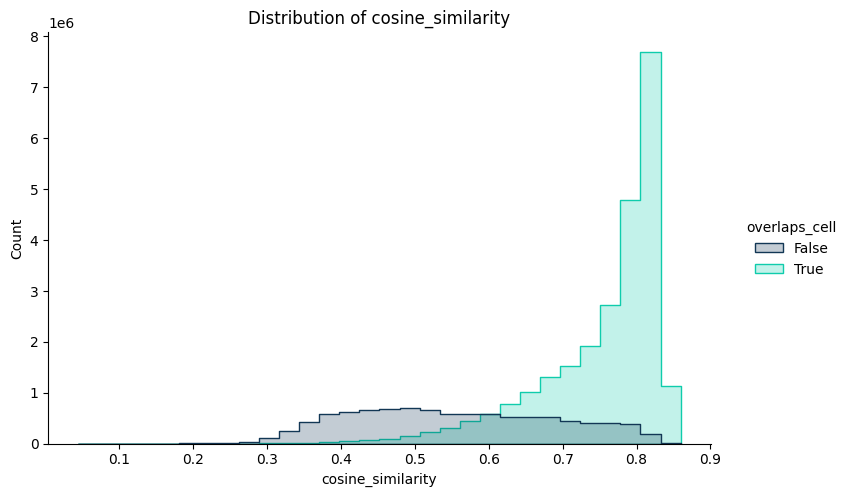

In [14]:
# 3)Histogram of scores
troutpy.pl.histogram(sdata,x='cosine_similarity',
        hue='overlaps_cell',palette='troutpy',save=False)

In [15]:
random_sim=sdata['transcripts'].loc[:,['cosine_similarity','overlaps_cell','y','x','closest_cell_type']].compute()

In [16]:
random_sim=sdata['transcripts'].loc[:,['cosine_similarity','overlaps_cell']].compute()
mean_random_sim=random_sim[random_sim['overlaps_cell']==False]['cosine_similarity'].mean()

In [17]:
mean_real_sim

0.5632473390231315

In [18]:
mean_random_sim

0.5540774278455336

# Exploring random distribution

In [19]:
troutpy.pp.define_urna(sdata, layer="transcripts", method="sainsc", copy=False, percentile_threshold=10)

Cosine similarity threshold for extracellular definition: 0.6345242857933044


No transformation matrix found. Proceeding without transformation.


(<Figure size 800x800 with 2 Axes>,
 <Axes: title={'center': 'Cell Boundaries + Transcripts'}>)

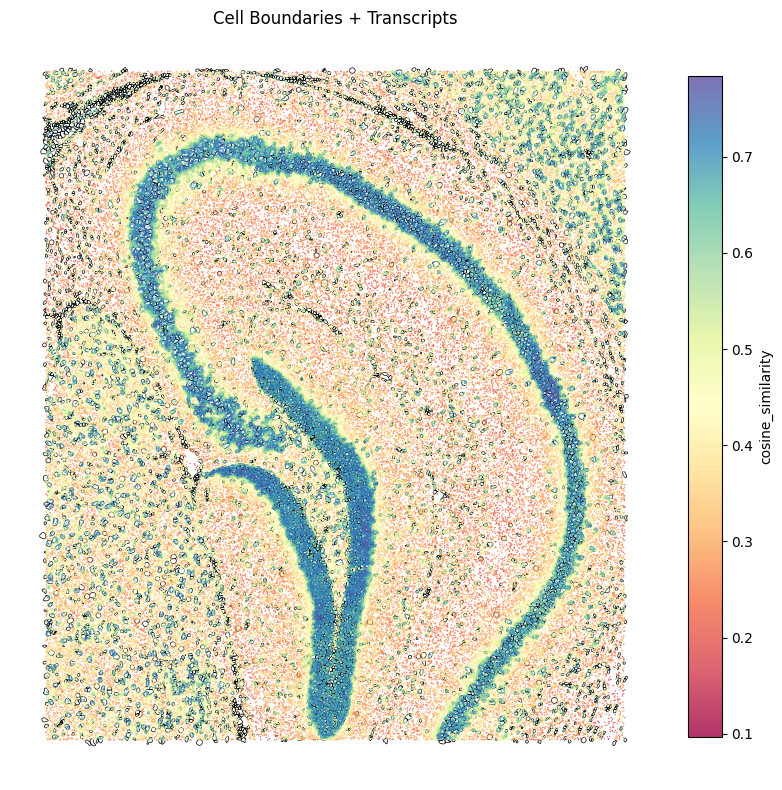

In [78]:
troutpy.pl.spatial_transcripts(sdata,color_key='cosine_similarity',colormap='Spectral',gene_list=['Camk2a'])

In [ ]:
real_sim

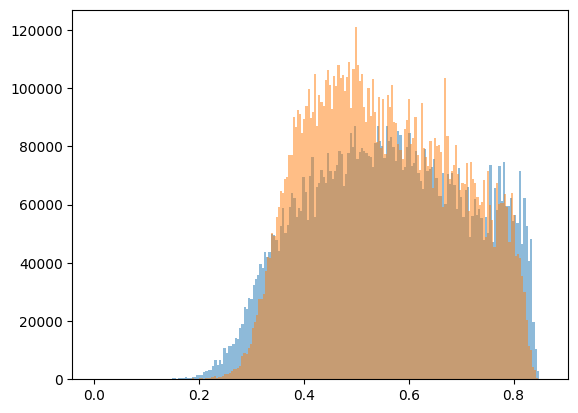

In [21]:
bins=plt.hist(real_sim.loc[real_sim['overlaps_cell']==False,'cosine_similarity'],bins=200,alpha=0.5)
bins=plt.hist(random_sim.loc[random_sim['overlaps_cell']==False,'cosine_similarity'],bins=200,alpha=0.5)

In [ ]:
troutpy.pl.spatial_transcripts(sdata,color_key='cosine_similarity',colormap='Spectral')

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Example: random_sim is your DataFrame with columns: 'x', 'y', 'closest_celltype'
# Get unique cell types
cell_types = random_sim['closest_cell_type'].unique()

# Set up the figure
n_cols = 4  # You can change this depending on how many subplots per row you want
n_rows = (len(cell_types) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows), squeeze=False)

# Plot each cell type
for idx, cell_type in enumerate(cell_types):
    row, col = divmod(idx, n_cols)
    ax = axes[row][col]
    subset = random_sim[random_sim['closest_cell_type'] == cell_type]
    sns.scatterplot(data=subset, x='x', y='y', ax=ax, s=5)
    ax.set_title(cell_type)
    ax.set_aspect('equal')
    ax.axis('off')

# Remove unused subplots if any
for idx in range(len(cell_types), n_rows * n_cols):
    row, col = divmod(idx, n_cols)
    axes[row][col].axis('off')

plt.tight_layout()
plt.show()


KeyError: 'closest_cell_type'

In [107]:
    # --- 0. Extract transcript table with overlaps_cell ---
transcripts_all = sdata.points["transcripts"].compute().reset_index(drop=True)
assert "overlaps_cell" in transcripts_all.columns, "`overlaps_cell` column is missing"

outputs_combined = []
sainsc_outputs = {}

In [113]:
overlap_value=False
        # Subset transcripts
subset_df = transcripts_all[transcripts_all["overlaps_cell"] == overlap_value].copy()

        # --- Create polars version ---
subset_pl = pl.from_pandas(subset_df[["gene", "x", "y"]].copy(), schema_overrides={"gene": pl.Categorical})

In [115]:
celltype_key='leiden'

# --- Load expression signatures ---
adata = sdata["table"]
expr = adata.to_df()
expr["cell type"] = adata.obs[celltype_key]
signatures = expr.groupby("cell type").mean().transpose()

In [117]:
# --- Select genes ---
common_genes = set(subset_df["gene"].unique()).intersection(set(signatures.index))
transcripts_analysis = subset_pl.filter(pl.col("gene").is_in(list(common_genes)))
signatures = signatures.loc[signatures.index.isin(common_genes), :]

In [128]:
len(list(common_genes))

4885

In [136]:
n_threads=2
binsize=50
resolution=1000
gaussian_kernel_key=2.5
background_filter=0.4

In [132]:
# --- Run KDE pipeline ---
brain = LazyKDE.from_dataframe(transcripts_analysis, resolution=resolution, binsize=binsize, n_threads=n_threads)

# Binning
_, shape, transcript2bin_info = process_dataframe(subset_pl, binsize=binsize, n_threads=n_threads)
transcript2bin_info = transcript2bin_info.to_pandas()
transcript2bin_info["bin_x_y_id"] = transcript2bin_info["bin_x"].astype(str) + "_" + transcript2bin_info["bin_y"].astype(str)

In [133]:


# Round coords
subset_df["x"] = subset_df["x"].round(4)
subset_df["y"] = subset_df["y"].round(4)
transcript2bin_info["x"] = transcript2bin_info["x"].round(4)
transcript2bin_info["y"] = transcript2bin_info["y"].round(4)
subset_df["xy"] = subset_df["x"].astype(str) + "_" + subset_df["y"].astype(str)
transcript2bin_info["xy"] = transcript2bin_info["x"].astype(str) + "_" + transcript2bin_info["y"].astype(str)

# Celltype assignment
brain.calculate_total_mRNA()


In [137]:


brain.gaussian_kernel(gaussian_kernel_key, unit="um")
brain.calculate_total_mRNA_KDE()
brain.filter_background(background_filter)
brain.assign_celltype(signatures, log=True)

        # Bin-level output
celltype_flat = brain.celltype_map.flatten()
assignment_score_flat = brain.assignment_score.flatten()
cosine_similarity_flat = brain.cosine_similarity.flatten()
n_rows, n_cols = brain.celltype_map.shape
x_coords, y_coords = np.meshgrid(np.arange(n_cols), np.arange(n_rows))
x_coords = x_coords.flatten()
y_coords = y_coords.flatten()
output_df = pd.DataFrame(
            {
                "bin_x": x_coords,
                "bin_y": y_coords,
                "cell type": celltype_flat,
                "assignment_score": assignment_score_flat,
                "cosine_similarity": cosine_similarity_flat,
            }
        )

In [139]:
num2ct = dict(zip(range(len(brain.celltypes)), brain.celltypes, strict=False))
output_df["cell type"] = output_df["cell type"].map(num2ct)
output_df["bin_x_y_id"] = output_df["bin_y"].astype(str) + "_" + output_df["bin_x"].astype(str)

        # Mapping
bin2celltype = dict(zip(output_df["bin_x_y_id"], output_df["cell type"], strict=False))
bin2cosine = dict(zip(output_df["bin_x_y_id"], output_df["cosine_similarity"], strict=False))
bin2assign = dict(zip(output_df["bin_x_y_id"], output_df["assignment_score"], strict=False))

        # Merge
bin_features = transcript2bin_info[["xy", "bin_x_y_id"]].drop_duplicates()
bin_features["closest_cell_type"] = bin_features["bin_x_y_id"].map(bin2celltype)
bin_features["cosine_similarity"] = bin_features["bin_x_y_id"].map(bin2cosine)
bin_features["assignment_score"] = bin_features["bin_x_y_id"].map(bin2assign)

In [146]:
cols_to_drop = [col for col in bin_features.columns if col in subset_df.columns and col != "xy"]
clean_subset = subset_df.drop(columns=cols_to_drop)
merged = pd.merge(clean_subset, bin_features, on="xy", how="left")


In [147]:
# Nearest-neighbor for failed
missing_mask = merged["closest_cell_type"].isna()
if missing_mask.sum() > 0:
    valid = merged[~missing_mask]
    missing = merged[missing_mask]
    if not valid.empty:
        tree = KDTree(valid[["x", "y"]].values)
        distances, indices = tree.query(missing[["x", "y"]].values, k=1)
        nn_metadata = valid.iloc[indices.flatten()].reset_index(drop=True)
        for col in ["closest_cell_type", "cosine_similarity", "assignment_score"]:
            missing[col] = nn_metadata[col].values
        merged.loc[missing_mask, ["closest_cell_type", "cosine_similarity", "assignment_score"]] = missing[
                    ["closest_cell_type", "cosine_similarity", "assignment_score"]
                ]


In [23]:
def segmentation_free_sainsc_by_overlap(
    sdata,
    binsize=3,
    celltype_key="leiden",
    background_filter=0.4,
    gaussian_kernel_key=2.5,
    n_threads=16,
    resolution=1000,
    codeword_category="predesigned_gene",
    return_sainsc=False,
    copy=False,
    default_cell_type="unknown",
    default_numeric=np.nan,
):
    from copy import deepcopy

    sdata = deepcopy(sdata) if copy else sdata

    # --- 0. Extract transcript table with overlaps_cell ---
    transcripts_all = sdata.points["transcripts"].compute().reset_index(drop=True)
    assert "overlaps_cell" in transcripts_all.columns, "`overlaps_cell` column is missing"

    outputs_combined = []
    sainsc_outputs = {}

    for overlap_value in [True, False]:
        # Subset transcripts
        subset_df = transcripts_all[transcripts_all["overlaps_cell"] == overlap_value].copy()

        # Skip if empty
        if subset_df.empty:
            continue

        # --- Create polars version ---
        subset_pl = pl.from_pandas(subset_df[["gene", "x", "y"]].copy(), schema_overrides={"gene": pl.Categorical})

        # --- Load expression signatures ---
        adata = sdata["table"]
        expr = adata.to_df()
        expr["cell type"] = adata.obs[celltype_key]
        signatures = expr.groupby("cell type").mean().transpose()

        # --- Select genes ---
        common_genes = set(subset_df["gene"].unique()).intersection(set(signatures.index))
        transcripts_analysis = subset_pl.filter(pl.col("gene").is_in(list(common_genes)))
        signatures = signatures.loc[signatures.index.isin(common_genes), :]

        # --- Run KDE pipeline ---
        brain = LazyKDE.from_dataframe(transcripts_analysis, resolution=resolution, binsize=binsize, n_threads=n_threads)

        # Binningga
        _, shape, transcript2bin_info = process_dataframe(subset_pl, binsize=binsize, n_threads=n_threads)
        transcript2bin_info = transcript2bin_info.to_pandas()
        transcript2bin_info["bin_x_y_id"] = transcript2bin_info["bin_x"].astype(str) + "_" + transcript2bin_info["bin_y"].astype(str)

        # Round coords
        subset_df["x"] = subset_df["x"].round(4)
        subset_df["y"] = subset_df["y"].round(4)
        transcript2bin_info["x"] = transcript2bin_info["x"].round(4)
        transcript2bin_info["y"] = transcript2bin_info["y"].round(4)
        subset_df["xy"] = subset_df["x"].astype(str) + "_" + subset_df["y"].astype(str)
        transcript2bin_info["xy"] = transcript2bin_info["x"].astype(str) + "_" + transcript2bin_info["y"].astype(str)

        # Celltype assignment
        brain.calculate_total_mRNA()
        brain.gaussian_kernel(gaussian_kernel_key, unit="um")
        brain.calculate_total_mRNA_KDE()
        brain.filter_background(background_filter)
        brain.assign_celltype(signatures, log=True)

        # Bin-level output
        celltype_flat = brain.celltype_map.flatten()
        assignment_score_flat = brain.assignment_score.flatten()
        cosine_similarity_flat = brain.cosine_similarity.flatten()
        n_rows, n_cols = brain.celltype_map.shape
        x_coords, y_coords = np.meshgrid(np.arange(n_cols), np.arange(n_rows))
        x_coords = x_coords.flatten()
        y_coords = y_coords.flatten()
        output_df = pd.DataFrame(
            {
                "bin_x": x_coords,
                "bin_y": y_coords,
                "cell type": celltype_flat,
                "assignment_score": assignment_score_flat,
                "cosine_similarity": cosine_similarity_flat,
            }
        )
        num2ct = dict(zip(range(len(brain.celltypes)), brain.celltypes, strict=False))
        output_df["cell type"] = output_df["cell type"].map(num2ct)
        output_df["bin_x_y_id"] = output_df["bin_y"].astype(str) + "_" + output_df["bin_x"].astype(str)

        # Mapping
        bin2celltype = dict(zip(output_df["bin_x_y_id"], output_df["cell type"], strict=False))
        bin2cosine = dict(zip(output_df["bin_x_y_id"], output_df["cosine_similarity"], strict=False))
        bin2assign = dict(zip(output_df["bin_x_y_id"], output_df["assignment_score"], strict=False))

        # Merge
        bin_features = transcript2bin_info[["xy", "bin_x_y_id"]].drop_duplicates()
        bin_features["closest_cell_type"] = bin_features["bin_x_y_id"].map(bin2celltype)
        bin_features["cosine_similarity"] = bin_features["bin_x_y_id"].map(bin2cosine)
        bin_features["assignment_score"] = bin_features["bin_x_y_id"].map(bin2assign)
        cols_to_drop = [col for col in bin_features.columns if col in subset_df.columns and col != "xy"]
        clean_subset = subset_df.drop(columns=cols_to_drop)
        merged = pd.merge(clean_subset, bin_features, on="xy", how="left")

        # Nearest-neighbor for failed
        missing_mask = merged["closest_cell_type"].isna()
        if missing_mask.sum() > 0:
            valid = merged[~missing_mask]
            missing = merged[missing_mask]
            if not valid.empty:
                tree = KDTree(valid[["x", "y"]].values)
                distances, indices = tree.query(missing[["x", "y"]].values, k=1)
                nn_metadata = valid.iloc[indices.flatten()].reset_index(drop=True)
                for col in ["closest_cell_type", "cosine_similarity", "assignment_score"]:
                    missing[col] = nn_metadata[col].values
                merged.loc[missing_mask, ["closest_cell_type", "cosine_similarity", "assignment_score"]] = missing[
                    ["closest_cell_type", "cosine_similarity", "assignment_score"]
                ]

        # Fill defaults
        merged["closest_cell_type"] = merged["closest_cell_type"].fillna(default_cell_type)
        merged["cosine_similarity"] = merged["cosine_similarity"].fillna(default_numeric)
        merged["assignment_score"] = merged["assignment_score"].fillna(default_numeric)

        # Standardize types
        merged["closest_cell_type"] = merged["closest_cell_type"].astype(str)
        merged["cosine_similarity"] = merged["cosine_similarity"].astype(float)
        merged["assignment_score"] = merged["assignment_score"].astype(float)

        # Save per split
        overlap_key = "intracellular" if overlap_value else "extracellular"
        sainsc_outputs[overlap_key] = {"brain": brain, "output_df": output_df, "transcript2bin_info": transcript2bin_info}
        outputs_combined.append(merged)

    # --- Merge all results back ---
    combined_df = pd.concat(outputs_combined, axis=0).sort_values("transcript_id")

    # --- Update sdata object ---
    transi = sdata.points["transcripts"].compute().copy()
    transi["xy"] = transi["x"].round(4).astype(str) + "_" + transi["y"].round(4).astype(str)
    cols_to_drop = [col for col in ["closest_cell_type", "cosine_similarity", "assignment_score"] if col in transi.columns]
    transi = transi.drop(columns=cols_to_drop)

    transi = pd.merge(
        transi,
        combined_df[["transcript_id", "closest_cell_type", "cosine_similarity", "assignment_score"]],
        on="transcript_id",
        how="left",
    )

    # Final safety fill
    transi["closest_cell_type"] = transi["closest_cell_type"].fillna(default_cell_type).astype(str)
    transi["cosine_similarity"] = transi["cosine_similarity"].fillna(default_numeric).astype(float)
    transi["assignment_score"] = transi["assignment_score"].fillna(default_numeric).astype(float)

    sdata.points["transcripts"] = sd.models.PointsModel.parse(transi)

    if return_sainsc:
        return sdata, sainsc_outputs
    else:
        return sdata if copy else None


In [ ]:
segmentation_free_sainsc_by_overlap(
    sdata=sdata,
    binsize=10,
    celltype_key="leiden",  # or your cell type annotation
    gaussian_kernel_key=2.0,
    background_filter=0.4,
    return_sainsc=False,    # True if you want access to internal objects
    copy=False              # True if you want to keep the input unchanged
)


In [ ]:
# 3)Histogram of scores
troutpy.pl.histogram(sdata,x='cosine_similarity',
        hue='overlaps_cell',palette='troutpy',save=False)

In [ ]:
troutpy.pl.spatial_transcripts(sdata,color_key='cosine_similarity',colormap='Spectral',gene_list=['Camk2a'])

In [ ]:
real_div_sim=sdata['transcripts'].loc[:,['cosine_similarity','overlaps_cell']].compute()
mean_real_div_sim=real_div_sim[real_div_sim['overlaps_cell']==False]['cosine_similarity'].mean()

In [ ]:
mean_real_div_sim

In [183]:
tran.loc[extracellular_indices, 'gene'][0:10]

0       Map2
1       Rbp1
10    Etnppl
12    Adarb1
13      Bcl6
15      Ncan
22     Nfat5
23      Mapt
26     Ntsr2
32     Ndrg2
Name: gene, dtype: category
Categories (13073, object): ['A1cf', 'A2m', 'Aatf', 'Abca1', ..., 'Zup1', 'Zyx', 'Zzef1', 'a']

In [ ]:
tran=sdata['transcripts'].compute()
# Get boolean mask for extracellular rows
mask = tran['overlaps_cell'] == False
# Get the indices where extracellular is True
extracellular_indices = tran.index[mask]
# Permute gene labels only for extracellular rows
permuted_genes = np.random.permutation(tran.loc[extracellular_indices, 'gene'].values)
# Assign the permuted gene labels back
tran.loc[extracellular_indices, 'gene'] = permuted_genes
sdata["transcripts"] = sd.models.PointsModel.parse(tran)

In [189]:
sdata["transcripts"]['gene'].compute()[extracellular_indices]

0            Aldoc
1            Ntsr2
10          Tecpr2
12            Rae1
13          Camk2b
             ...  
23790746     Rab5c
23790748    Eif4a3
23790749    Camta2
23790750      Phf3
23790751    Mycbp2
Name: gene, Length: 8350561, dtype: category
Categories (13073, object): ['A1cf', 'A2m', 'Aatf', 'Abca1', ..., 'Zup1', 'Zyx', 'Zzef1', 'a']

In [185]:
tran.loc[extracellular_indices, 'gene'].head(10)

0       Aldoc
1       Ntsr2
10     Tecpr2
12       Rae1
13     Camk2b
15      Vps28
22      Ndrg2
23      Rab3a
26    Timmdc1
32     Kcnab2
Name: gene, dtype: category
Categories (13073, object): ['A1cf', 'A2m', 'Aatf', 'Abca1', ..., 'Zup1', 'Zyx', 'Zzef1', 'a']

In [ ]:
segmentation_free_sainsc_by_overlap(
    sdata=sdata,
    binsize=10,
    celltype_key="leiden",  # or your cell type annotation
    gaussian_kernel_key=2.0,
    background_filter=0.4,
   areturn_sainsc=False,    # True if you want access to internal objects
    copy=False              # True if you want to keep the input unchanged
)


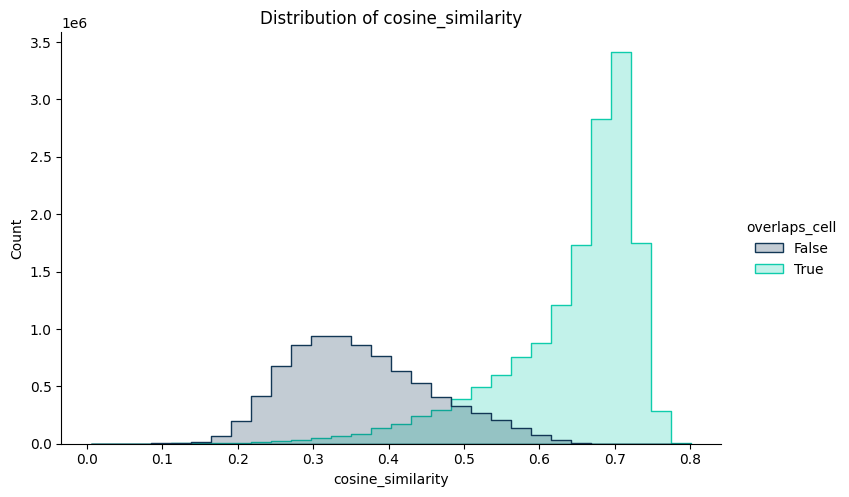

In [172]:
# 3)Histogram of scores
troutpy.pl.histogram(sdata,x='cosine_similarity',
        hue='overlaps_cell',palette='troutpy',save=False)

In [209]:
random_div_sim=sdata['transcripts'].loc[:,['cosine_similarity','overlaps_cell','closest_cell_type','x','y']].compute()
mean_random_div_sim=random_div_sim[random_div_sim['overlaps_cell']==False]['cosine_similarity'].mean()

In [214]:
random_div_sim[random_div_sim['overlaps_cell']==False].groupby('closest_cell_type').mean().sort_values(by='cosine_similarity')

,cosine_similarity,overlaps_cell,x,y
closest_cell_type,,,,
17,0.063763,0.0,4761.720215,2167.645752
20,0.160020,0.0,4886.729492,2196.120361
1,0.187145,0.0,5074.134766,1974.227173
10,0.190044,0.0,4983.007324,1987.255127
9,0.194129,0.0,4927.207031,1990.894043
6,0.202274,0.0,5130.286133,1828.652344
4,0.235337,0.0,4898.050293,1985.492188
19,0.242127,0.0,4985.274902,1967.036865
15,0.242216,0.0,4913.978516,1996.039917


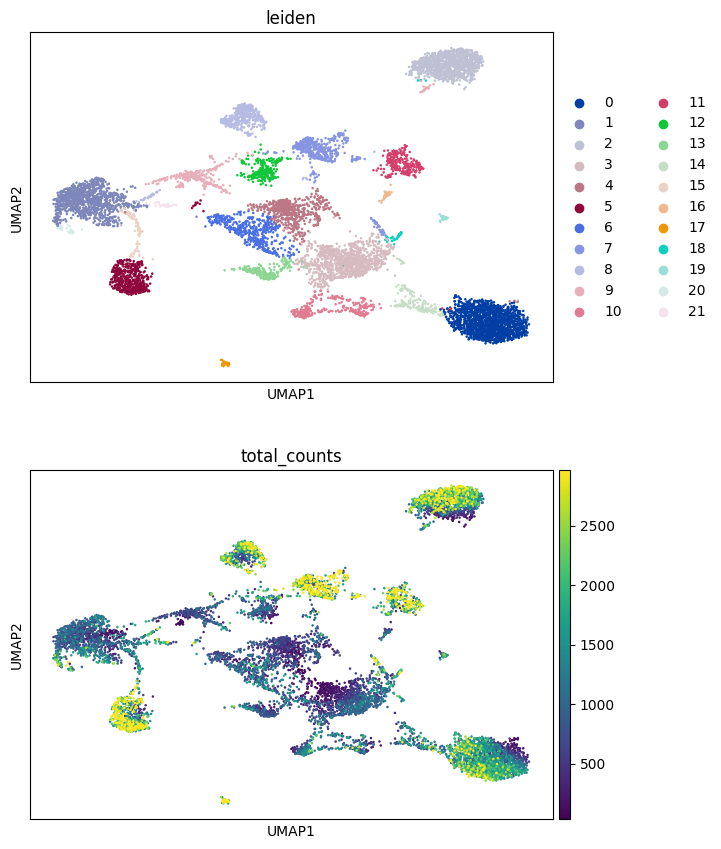

In [220]:
sc.pl.umap(sdata['table'],color=['leiden','total_counts'],vmax='p95',ncols=1)

In [227]:
sdata['table']

AnnData object with n_obs × n_vars = 9185 × 4886
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'n_genes', 'n_counts', 'leiden'
    var: 'gene_ids', 'feature_types', 'genome', 'gene_id', 'n_cells'
    uns: 'spatialdata_attrs', 'log1p', 'pca', 'neighbors', 'umap', 'leiden', 'dendrogram_leiden', 'rank_genes_groups', 'leiden_colors'
    obsm: 'spatial', 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'raw'
    obsp: 'distances', 'connectivities'

In [221]:
sc.tl.rank_genes_groups(sdata['table'],groupby='leiden')

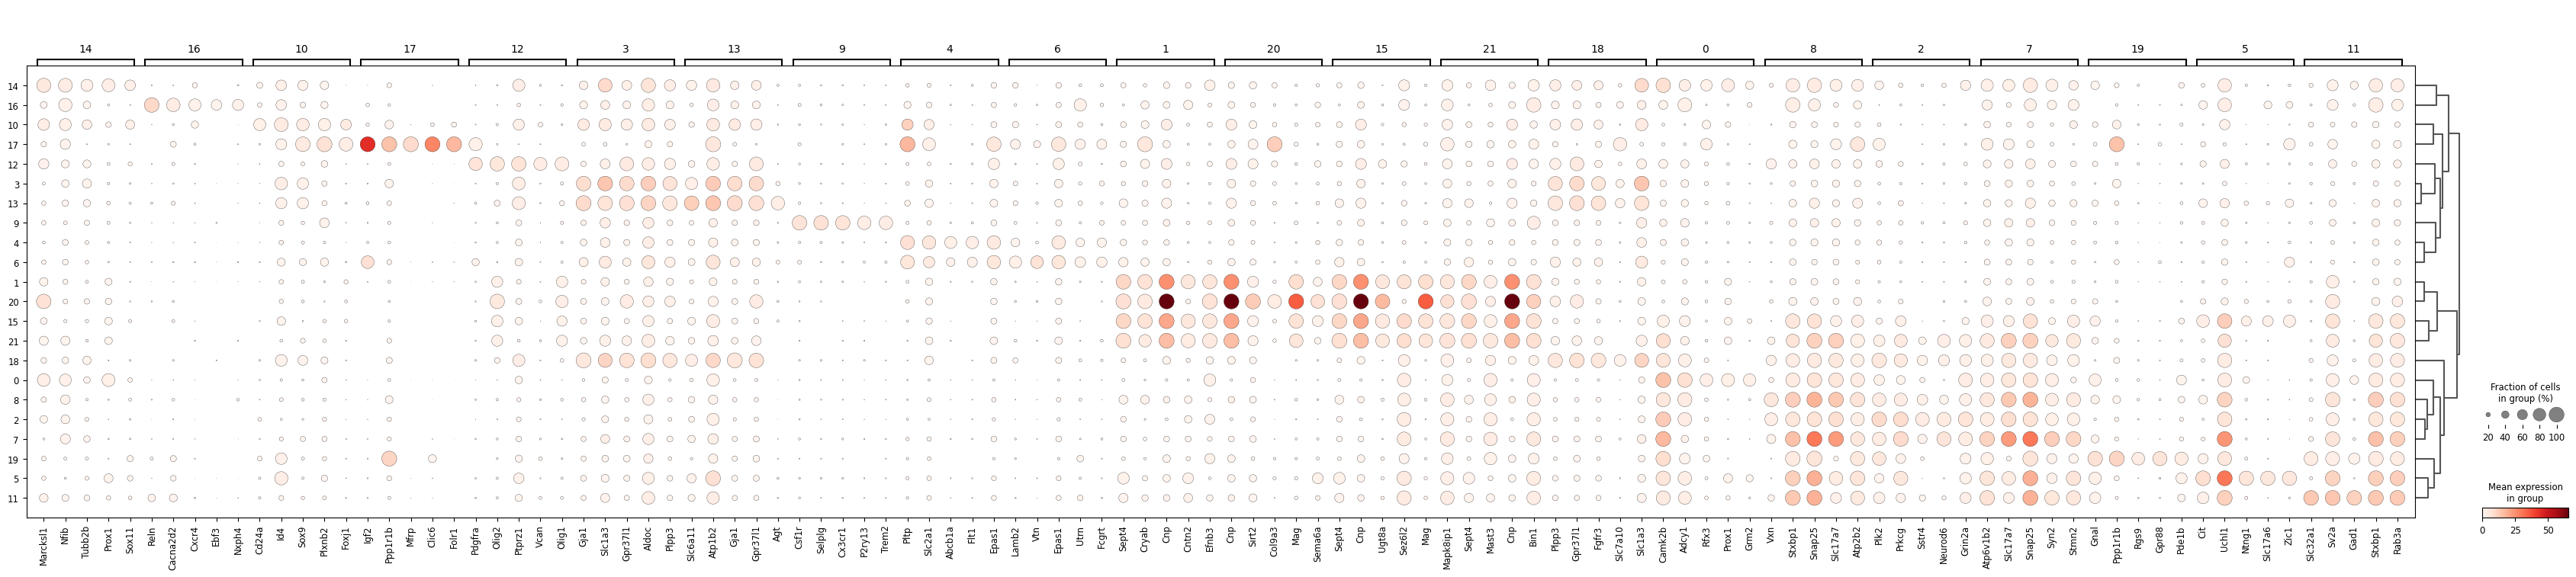

In [223]:
sc.pl.rank_genes_groups_dotplot(sdata['table'],groupby='leiden',n_genes=5)

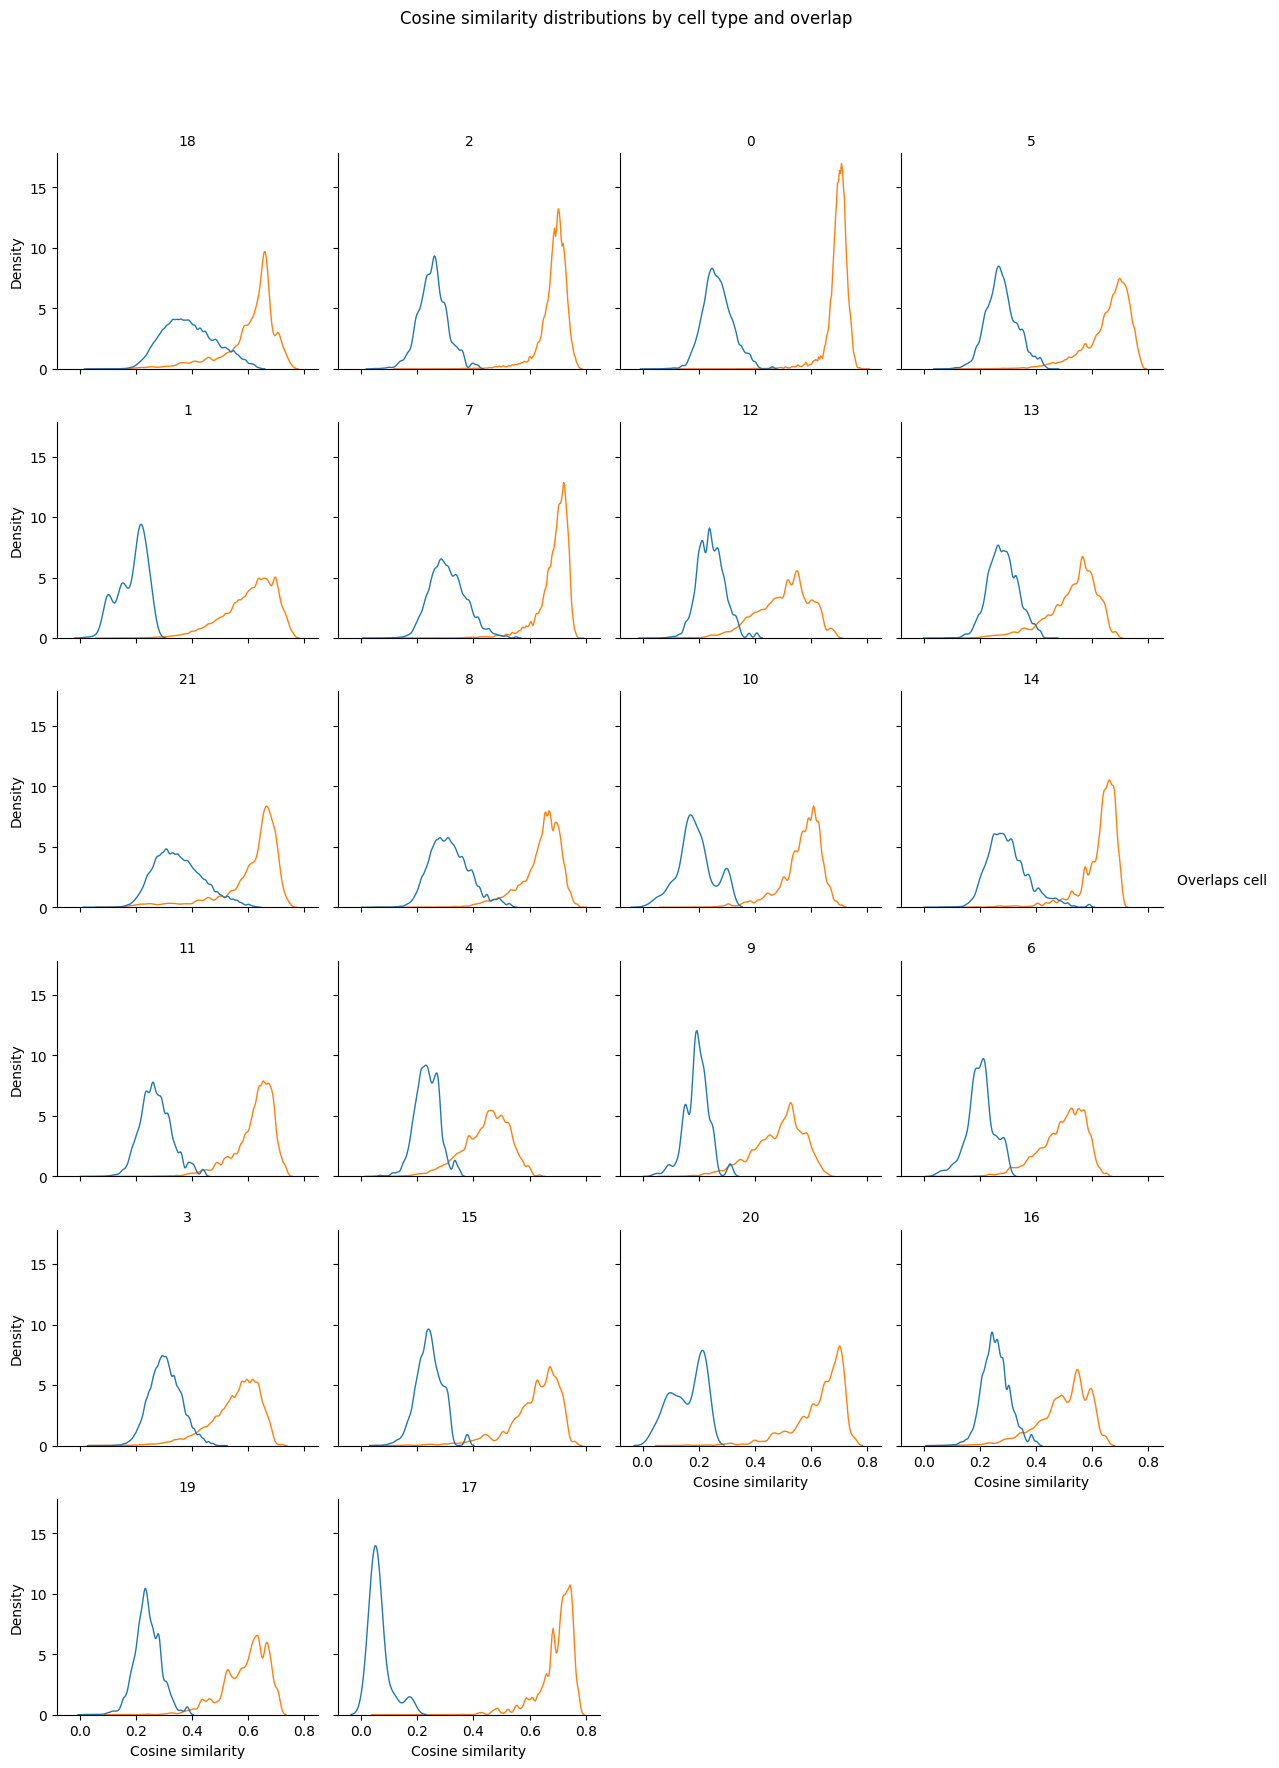

In [210]:
import seaborn as sns
import matplotlib.pyplot as plt

# Ensure the relevant column is boolean
random_div_sim["overlaps_cell"] = random_div_sim["overlaps_cell"].astype(bool)

# Convert closest_cell_type to string to ensure consistency
random_div_sim["closest_cell_type"] = random_div_sim["closest_cell_type"].astype(str)

# Set up FacetGrid: one subplot per cell type
g = sns.FacetGrid(
    random_div_sim,
    col="closest_cell_type",
    col_wrap=4,  # Adjust depending on how many cell types you have
    sharex=True,
    sharey=True,
    height=3,
)

# Map KDE plots to the FacetGrid
g.map_dataframe(
    sns.kdeplot,
    x="cosine_similarity",
    hue="overlaps_cell",
    common_norm=False,
    lw=1,
)

# Improve layout and add legend
g.add_legend(title="Overlaps cell")
g.set_axis_labels("Cosine similarity", "Density")
g.set_titles(col_template="{col_name}")
plt.subplots_adjust(top=0.9)
g.fig.suptitle("Cosine similarity distributions by cell type and overlap")

plt.show()


In [207]:
random_div_sim=random_div_sim[random_div_sim['overlaps_cell']==True]

In [ ]:
import seaborn as sns

plt.figure(figsize=(10, 6))
for ct in sorted(random_div_sim["closest_cell_type"].astype(str).unique()):
    rdf = random_div_sim[random_div_sim["closest_cell_type"].astype(str) == ct]
    sns.kdeplot(rdf["cosine_similarity"], label=f"{ct}", lw=1)

plt.xlabel("Cosine similarity")
plt.ylabel("Density")
plt.title("Cosine similarity distributions per cell type")
plt.legend(title="Cell type", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


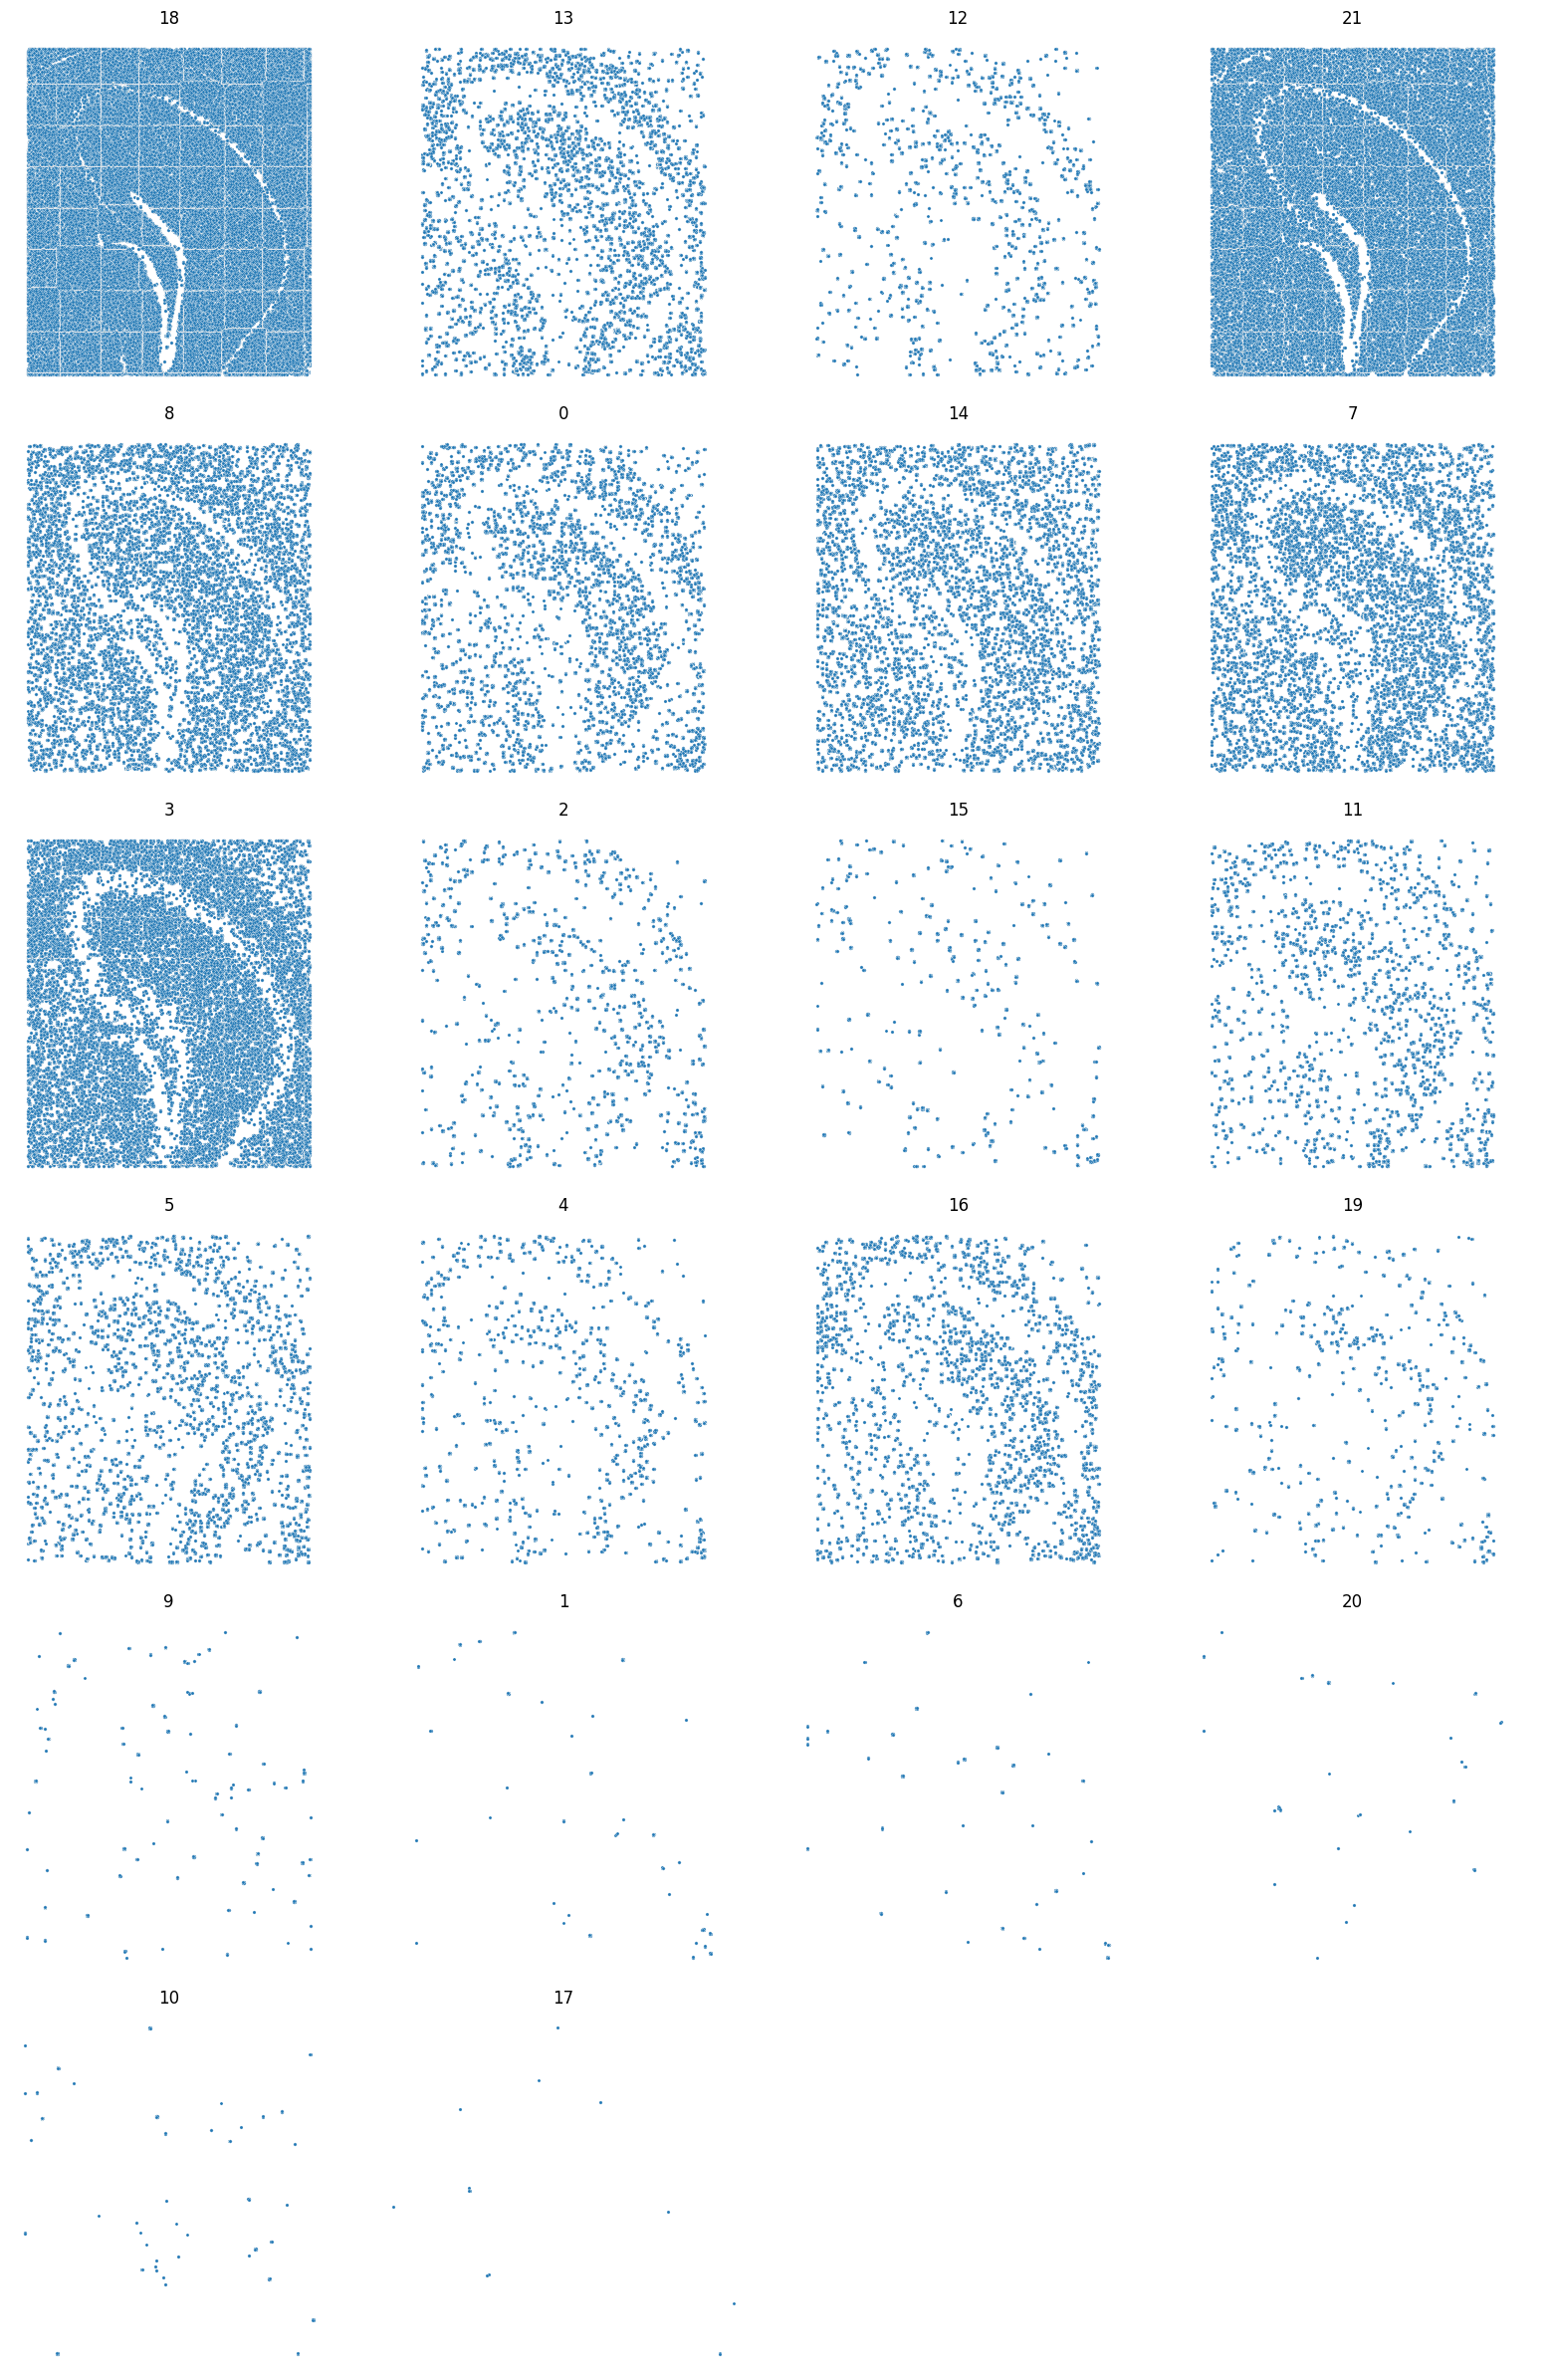

In [194]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Example: random_sim is your DataFrame with columns: 'x', 'y', 'closest_celltype'
# Get unique cell types
cell_types = random_div_sim['closest_cell_type'].unique()

# Set up the figure
n_cols = 4  # You can change this depending on how many subplots per row you want
n_rows = (len(cell_types) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows), squeeze=False)

# Plot each cell type
for idx, cell_type in enumerate(cell_types):
    row, col = divmod(idx, n_cols)
    ax = axes[row][col]
    subset = random_div_sim[random_div_sim['closest_cell_type'] == cell_type]
    sns.scatterplot(data=subset, x='x', y='y', ax=ax, s=5)
    ax.set_title(cell_type)
    ax.set_aspect('equal')
    ax.axis('off')

# Remove unused subplots if any
for idx in range(len(cell_types), n_rows * n_cols):
    row, col = divmod(idx, n_cols)
    axes[row][col].axis('off')

plt.tight_layout()
plt.show()
